## Authors:
- **Sebastián Kay Conde Lorenzo**
- **Carlos Antonio Sánchez-Beato Alonso**

---

## Part 1: Visualization of high-dimension binary entries.

We consider a genetic dataset: each entry is composed of $805$ binary inputs. Each input encode for a genetic mutation of a gene with respect to a common ancestor.
In this part, you have to do the following tasks:
1. Load the dataset into a matrix $X \in \mathbb{R}^{M \times D}$ where $M=4507$, and $D=805$.
2. Try to visualize the dataset ...
3. Compute $X_c$, the centered version of the dataset.
4. Using the principal directions $V$, find a way to visualize the dataset projecting it on 4 different directions. We could for instance show scatter plots of the dataset using $4$ directions (two plots, the first one plotting $1$ vs $2$ and the second one plotting $3$ vs $4$).
5. Load the labels associated to the datset into the vector $y$. Re-do the same plots but putting a different color for each different class.
6. Can the principal directions of the dataset be useful to characterize some of the classes ?

# Part I: PCA, SVD and dimensional reduction

The goal of this labwork is to study various aspect of the PCA (Principal Component Analysis) and the associate matrix factorization SVD (Singular Value Decomposition).

### A quick recall
#### PCA
Given a data matrix $X \in \mathbb{R}^{M \times D}$,
* first center the matrix: $X_c$ is the data matrix where each dimension has been centered to have mean zero: $x_{c,i}^{(m)} = x_i^{(m)} - \sum_m x_i^{(m)}  / M$;
* then, compute the covariance matrix $S = X_c^T X_c / M \in \mathbb{R}^{D \times D}$;
* finally, diagonalize the covariance matrix $S = V D V^T$.

The matrix $V$ contains the principal directions and the diagonal matrix $D$ the variances associated with each direction.

#### SVD
The SVD is now the following factorization $X_c = U \Sigma V^T$, it correspond to a decomposition on a given eigenbasis given by $V$. Now we can identify its link with the PCA
$$
  \frac{1}{M} X_c^T X_c = \frac{1}{M} V \Sigma^2 V^T
$$
and thus $V$ correponds to the matrix containing the principal directions while the values of the matrix sigma are related to the principal values as $\frac{1}{M} \sigma_\alpha^2 = d_{\alpha}$

### Imports

In [1]:
import numpy as np
import h5py
import matplotlib.pyplot as plt

### Task 1
Load the dataset into a matrix $X \in \mathbb{R}^{M \times D}$ where $M=4507$, and $D=805$. In this case, $D$ is the number of realizations ("training examples") and $M$ the number of features of each realization/training example.

In [2]:
# Load the dataset

fname = "DNA.h5"
# f works like a dictionary
f = h5py.File(fname,'r')
# we load the training set
X = f['train'][()]
y = f['train_labels'][()]
f.close()

print(X.shape)

(4507, 805)


#### Task 2
Let's try to visualize the dataset...

It is not easy to represent this data in an intepretable way without loosing information, because there are 805 binary variables. We may compute how many genetic mutations has each of the 4507 realizations by aggregating them by mutation and representing their frecuencies. This is, if the elements of $X$ are $x_{ij}=$ observation i has mutation j $\in\{0,1\}$, we compute $\sum_{j} x_{ij}$.

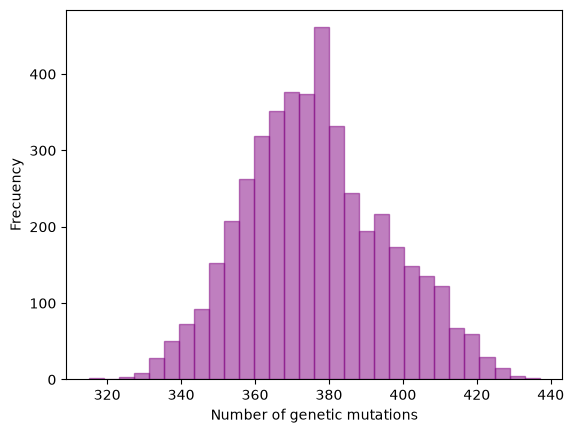

In [3]:
# we add the columns for each row (# mutations of each realization i)
sums = X.sum(axis=1)

plt.hist(sums, bins=30, color="purple", alpha=0.50, edgecolor="purple") # color, alpha and edgecolor are just for esthetics
plt.xlabel("Number of genetic mutations")
plt.ylabel("Frecuency")
plt.show()

In [4]:
print(min(sums), max(sums))

315 437


This approach does give some informartion: we now know that the number of genetic mutations in a given realization is between 315 and 437.

We can also add another plot that reveals what are the most common genetic mutations:

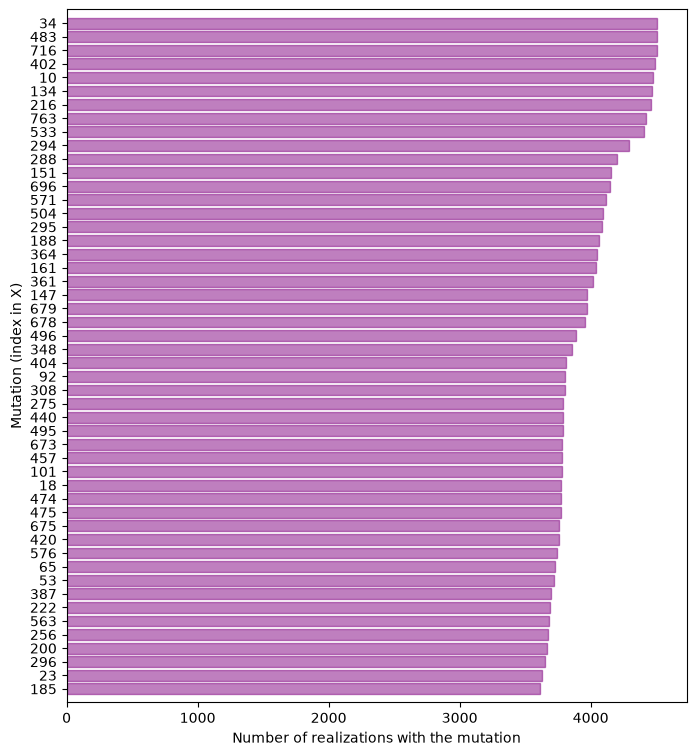

In [5]:
# We add the rows for each column (# realizations that have each mutation j)
mutation_counts = X.sum(axis=0)

# argsort orders from lowest to greatest, so we invert with [::-1]
order = np.argsort(mutation_counts)[::-1]

# We keep the {top} most common mutations
top = 50
top_mutations = order[:top]                 # {top} most common mutations (j)
top_counts = mutation_counts[top_mutations] # Frequency of {top} most common mutations

plt.figure(figsize=(8, 9))
plt.barh(np.array(range(top)), top_counts, color="purple", alpha=0.50, edgecolor="purple") 
plt.yticks(np.array(range(top)), top_mutations) # Set 'y' axis ticks
plt.ylim(top, -1)  # Inverted, so the most common mutation is on top

plt.xlabel("Number of realizations with the mutation")
plt.ylabel("Mutation (index in X)")
plt.show()

### Task 3

We are now asked to compute $X_c$, the centered version of the dataset.

The matrix $X_c=(x^{c}_{ij})_{i,j}$ is given by $$x^{c}_{ij} = x_{ij} - \frac{1}{M}\sum_{i=1}^M x_{ij}.$$ This is, for each mutation $j$, we substract the average on every realization. For this, we use numpy's matrix calculus (which saves us from doing a double loop).


In [6]:
M, D = X.shape

# Mean of each feature
averages = X.mean(axis=0)

# Centered matrix
X_c = X - averages

### Task 4

Using the principal directions $V$, we are asked to find a way to visualize the dataset projecting it on 4 different directions. We could, for instance, show scatter plots of the dataset using $4$ directions (two plots, the first one plotting $1$ vs $2$ and the second one plotting $3$ vs $4$).

We begin by computing the covariance matrix. As we know, this is $S=\frac{1}{M}X_{c}^T X_{c}$. With numpy, the matrix multiplication is given by ```@```.

In [7]:
X_c_T = X_c.T
S=(1/M)*(X_c_T@X_c)

Now we need to find the eigenvectors of the linear map defined by $S$. We know that $S$ is simetric and semidefinite-positive, so we will get (since $S\in\mathbb{R}^{D \times D}$) $D$ real non-negative eigenvalues and a basis of D orthogonal eigenvectors.

In [8]:
eigenvalues, eigenvectors = np.linalg.eigh(S)

With this computation, we get that ```eigenvalues[i]``` is the eigenvalue of the eigenvector ```eigenvectors[:,i]```. So, the greatest eigenvalues (ordered) are the following, with their correspondending principal directions (the first line of the following code is the ordering of the eigenvalues):

In [9]:
# argsort orders by index from lowest to greatest, so we invert with [::-1]
idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

We project the data set on each one of the four directions with greatest eigenvalues. This is, for each realization $x_c^{(m)}\in\mathbb{R}^{D}$, we project $x_c^{(m)}$ in the eigenvector $v_k$. For $$c_k^{(m)} = \langle x_c^{(m)}, v_k \rangle$$
the projected vector is $$z_k=c_k^{(m)}v_k.$$

If $V\in\mathbb{R}^{D\times 4}$ is the matrix wich columns are the four biggest eigenvectors, we can do the computation through $$Z = X_c V \in \mathbb{R}^{M \times 4}$$  This is, $Z=(c_k^{(m)})_{k,m}.$

In [10]:
V = eigenvectors[:, :4]
Z = X_c @ V
Z.shape # Shape checking for sanity

(4507, 4)

Now we can plot the results as suggested:

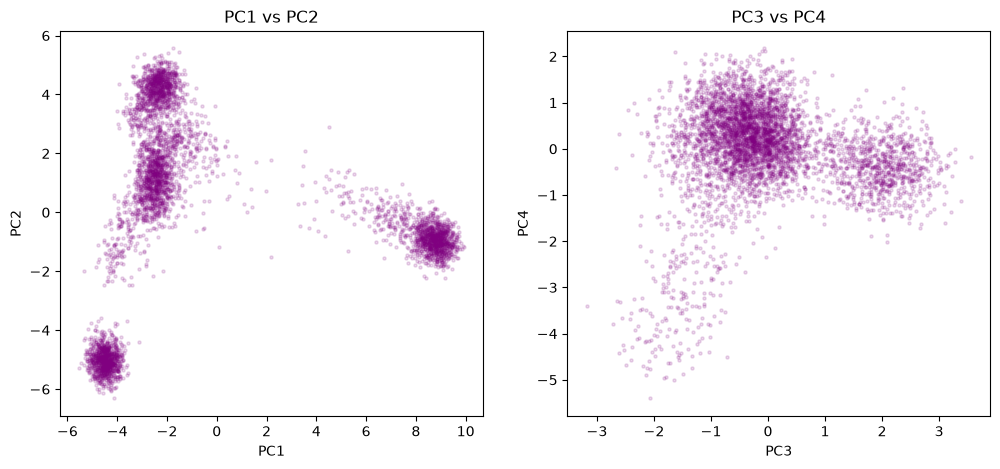

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))

ax[0].scatter(Z[:,0], Z[:,1], s=5, color="purple", alpha=0.15, edgecolor="purple") # color, alpha and edgecolor just for esthetics
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[0].set_title("PC1 vs PC2")

ax[1].scatter(Z[:,2], Z[:,3], s=5, color="purple", alpha=0.15, edgecolor="purple")
ax[1].set_xlabel("PC3")
ax[1].set_ylabel("PC4")
ax[1].set_title("PC3 vs PC4")

plt.show()

Let us do a quick comment on the previous graph. For this, some previous context:

Let $\lambda_k$ be the eigenvalue of $S$ associated with the unit eigenvector $v_k$, so that $S v_k = \lambda_k v_k$. Since $X_c$ is centered, the projections $X_c v_k$ have zero mean, so their variance is
$$\frac{1}{M}\lVert X_c v_k \rVert^2 = v_k^T \left(\frac{1}{M} X_c^T X_c\right) v_k = v_k^T S v_k = \lambda_k v_k^T v_k = \lambda_k.$$
That is, the variance of the dataset along the direction $v_k$ is exactly $\lambda_k$.

On the other hand, the total variance of the dataset is the sum of the variances of all the mutations, which are the diagonal elements of $S$. Since the trace of a matrix equals the sum of its eigenvalues,
$$\sum_{j=1}^{D} S_{jj} = \mathrm{tr}(S) = \sum_{j=1}^{D} \lambda_j.$$

Therefore, the direction $v_k$ captures a fraction $\lambda_k / \sum_{j} \lambda_j$ of the total variance. These fractions can be added, because the principal directions are uncorrelated: for $k \neq l$, $v_k^T S v_l = \lambda_l v_k^T v_l = 0$.

In [12]:
# Fraction of the total variance captured by each principal direction
explained = eigenvalues / eigenvalues.sum()

print(f"PC1 + PC2: {100 * (explained[0] + explained[1])}%")
print(f"PC3 + PC4: {100 * (explained[2] + explained[3])}%")

PC1 + PC2: 21.05919485640422%
PC3 + PC4: 1.3410705731207069%


PC1 vs PC2 shows several well-separated clusters, which suggests that the realizations belong to distinct groups. In PC3 vs PC4 the clusters overlap much more. This is expected: direction $k$ captures a fraction $\lambda_k / \sum_j \lambda_j$ of the total variance, which gives 21.06% for PC1 and PC2 together but only 1.34% for PC3 and PC4.

### Task 5

Let's load the labels associated to the datset into the vector $y$. We'll re-do the same plots but putting a different color for each different class.

In [13]:
classes = np.unique(y)
print(classes)

[b'African' b'American' b'East Asian' b'European' b'South Asian']


Notice that labels are continents of origin. Let´s see their implication on the spread of the scatter plots.

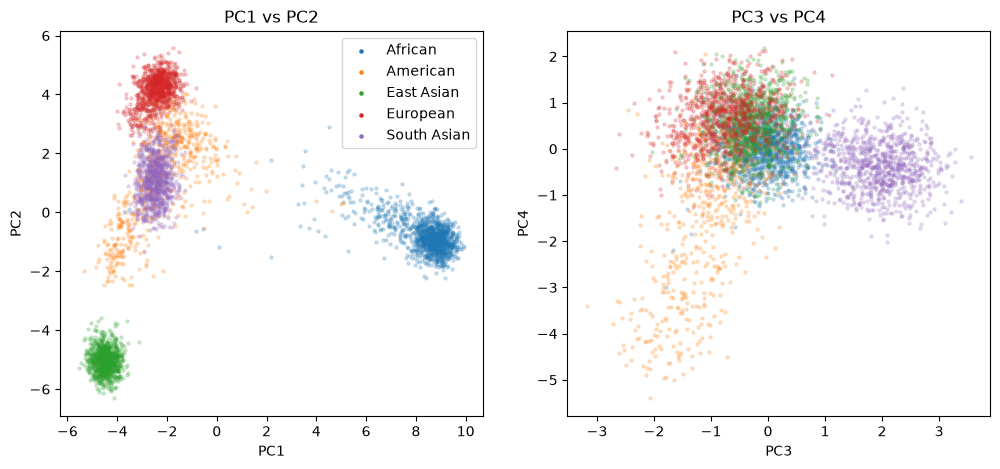

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))

classes = np.unique(y)

for i, c in enumerate(classes):
    mask = (y == c)
    color = f"C{i}" # i-th color of matplotlib's default palette

    ax[0].scatter(Z[mask,0], Z[mask,1], s=5, color=color, alpha=0.20, edgecolor=color, label=c.decode())
    ax[1].scatter(Z[mask,2], Z[mask,3], s=5, color=color, alpha=0.20, edgecolor=color, label=c.decode())

ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[0].set_title("PC1 vs PC2")

ax[1].set_xlabel("PC3")
ax[1].set_ylabel("PC4")
ax[1].set_title("PC3 vs PC4")

legend = ax[0].legend()
for handle in legend.legend_handles:
    handle.set_alpha(1) # The legend would inherit alpha=0.15 otherwise

plt.show()

We notice that the clusters shown by the previous scatter plots can be understood through the countries labels.

### Task 6

We are asked now: can the principal directions of the dataset be useful to characterize some of the classes?

Indeed, the principal directions can be usefull to characterize classes. For instance, we may use as a toy choosing rule for a given realization $x$ that if $\operatorname{PC2}(x)<-3$, then $x$ is from East Asia. If $\operatorname{PC1}(x)>3$ there is a high chance of $x$ being African, and the same for $\operatorname{PC3}(x)>1$ and South Asian. Also, if $\operatorname{PC4}(x) < -1.5$ then there is a chance that $x$ is American, and if $\operatorname{PC2}(x) > 1$ that it is European.

We can quantify how good this toy rule is by computing the precission and the recall: Precision is the fraction of the realizations selected by the rule that belong to the class, and recall is the fraction of the class that is selected by the rule. Obviously, this all pretty optimistic and (as we said) toy-like because we are setting this thresholds by eye and also we are evaluating on the training set.

In [15]:
# Each rule is a threshold on a single principal direction
rules = {
    "East Asian":  Z[:,1] < -3,
    "African":     Z[:,0] > 3,
    "South Asian": Z[:,2] > 1,
    "American":    Z[:,3] < -1.5,
    "European":    Z[:,1] > 3,
}

for name, selected in rules.items():
    in_class = (y == name.encode())    # We need to use .encode() because y[i] is of type numpy.bytes_
    hits = (selected & in_class).sum() # & is a bitwise and (selected is a an array of booleans and in_class is too!)
    print(f"{name}: precision = {100 * hits / selected.sum()}%, recall = {100 * hits / in_class.sum()}%")

East Asian: precision = 100.0%, recall = 100.0%
African: precision = 99.66130397967824%, recall = 99.40878378378379%
South Asian: precision = 98.81516587677726%, recall = 94.88054607508532%
American: precision = 93.4156378600823%, recall = 36.4951768488746%
European: precision = 91.41361256544502%, recall = 95.93406593406593%


---

# Part 2: SVD and Compression

In this part we want to show how the SVD can be use to compress a dataset. In order to be visual, we will consider the dataset Fashion MNIST, which consists in pictures of clothes in black and white.
Use the next cell to load the dataset.

Remind that the SVD can be written as (assuming $M>D$)
$$
    X_{c,i}^{(m)} = \sum_{\alpha=1}^D u_{m \alpha} \sigma_{\alpha} v_{\alpha i} = \sum_{\alpha=1}^D \vec{u}_\alpha \sigma_{\alpha} \vec{v}_{\alpha}^{\top}
$$



In [16]:
# Load data
from sklearn.datasets import fetch_openml

# Download Fashion-MNIST (as 784-dimensional vectors)
fashion = fetch_openml('Fashion-MNIST', version=1, as_frame=False)
X, y = fashion['data'], fashion['target'].astype(int)

# X is a set of 70.000 images of 28x28=784 pixels
# this is represented as a vector in R^784

# Normalize (so black intensity is between 0 and 1)
X = X / 255.0

# Optional: reshape to images (matrix 28x28)
X_reshaped = X.reshape(-1, 28, 28)

print("Shape:", X.shape, "Labels:", np.unique(y))

Shape: (70000, 784) Labels: [0 1 2 3 4 5 6 7 8 9]


Do the following tasks:
1. plot a random subset of $25$ images of the dataset.
2. We consider now the centered dataset, and the SVD decomposition of the centered matrix $X_c$.
3. Using the function `np.linalg.svd` perform the SVD decomposition of $X_c$
4. Make a plot of the first $25$ principal directions (the ones associated with the largest variances). Do you recognize something ?
5. Try to reproduce the same scatter plot as in the first part. Can it be use to characterize some classes ?
6. We now want to try to compress the dataset by removing information that would encode noise. Justify that we can write
$$\boldsymbol X=\begin{bmatrix}
\vec{x}_1^{\top} \\
\vec{x}_2^{\top} \\
\vdots \\
\vec{x}_M^{\top} \\
\end{bmatrix}=\overline{\boldsymbol X}+\sum_\alpha \sigma_{\alpha} \vec{u}_\alpha \vec{v}_\alpha^\top$$
7. By removing in the summation over $\alpha$, the directions that counts for small variance, look what happen if you conserve the $[5,10,50,200]$ directions with the largest possible values of $\sigma_{\alpha}$. To perform this opeation, consider a set of $10$ images, and show the resulting images. You can make a plot where each line corresponds to a samples that is reconstruted with more and more eigendirections (in column).

### Task 1

Let's plot a random subset of 25 images of the dataset. Notice we are not setting any seed, so every execution of this cell will yield a different subset.

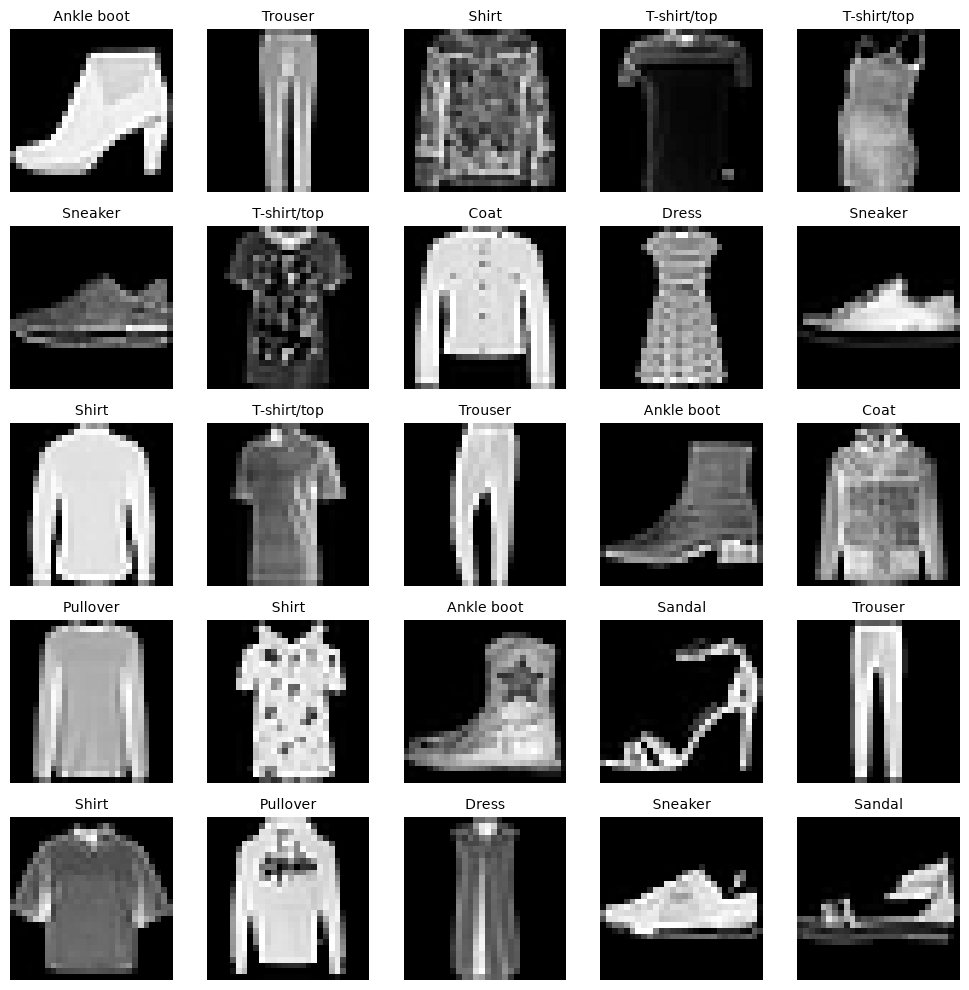

In [17]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"] # Class names from official docs online!

index = np.random.choice(X_reshaped.shape[0], size=25, replace=False)

fig, axes = plt.subplots(5, 5, figsize=(10, 10))

for ax, idx in zip(axes.ravel(), index):
    ax.imshow(X_reshaped[idx], cmap="gray")
    ax.set_title(class_names[y[idx]], fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Task 2

We consider now the centered dataset, and the SVD decomposition of the centered matrix $X_c$.

For centering the data set we do the same that we did in part I:

In [18]:
M, D = X.shape

# Media de cada feature/píxel
averages = X.mean(axis=0)

# Matriz centrada
X_c = X - averages

### Task 3

Using the function `np.linalg.svd`, we perform the SVD decomposition of $X_c$

In [19]:
U, singular_values, Vt = np.linalg.svd(X_c, full_matrices=False)

We can see on the documentation of the function `np.linalg.svd` that it does not return the singular values diagonal matrix, but the signular values ordered from greatest to lowest.

### Task 4

Let's make a plot of the first $25$ principal directions (the ones associated with the largest variances). First notice that principal vectors $v_k\in\mathbb{R}^{784}$ can be represented as pixel matrices in $\mathbb{R}^{28\times 28}.$ This is, as images.

For plotting, we use `"seismic"`, where red is asociated to positive coordinates (more intense the red, more positive), blue to negative and white to zero.

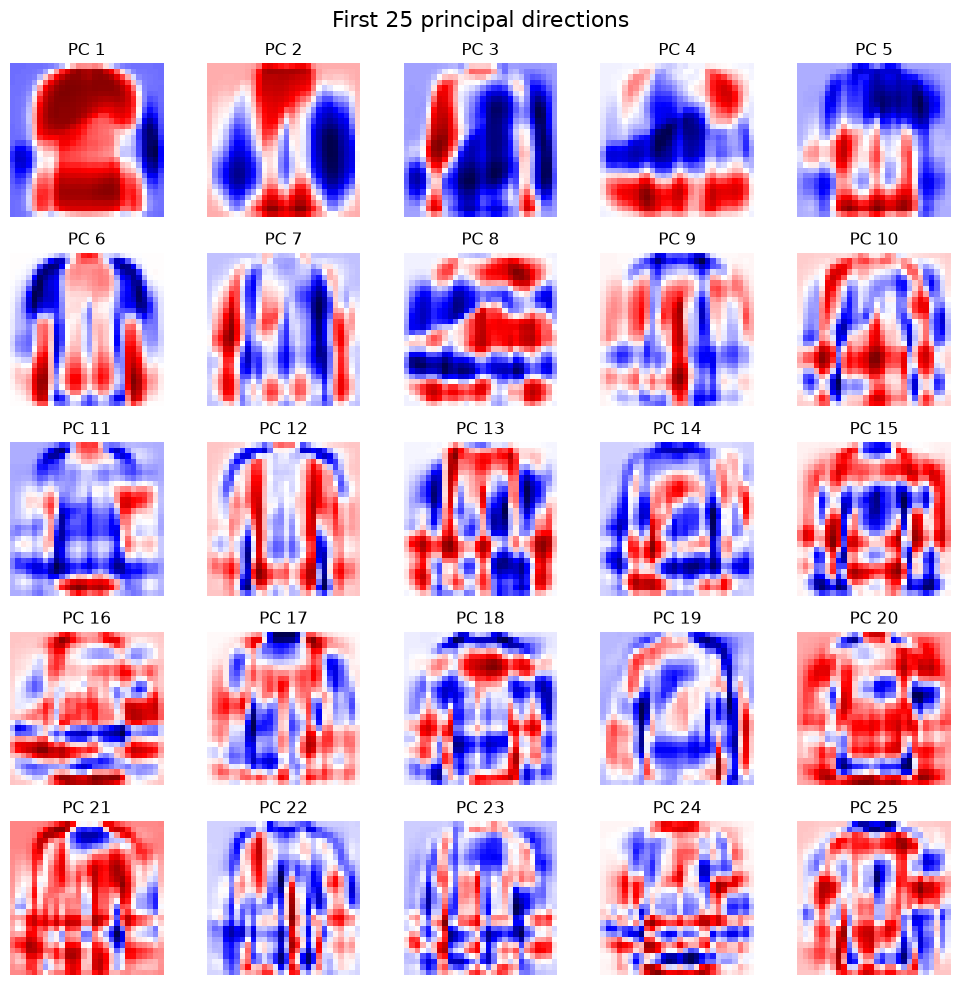

In [20]:
fig, axes = plt.subplots(5, 5, figsize=(10, 10))

for k, ax in enumerate(axes.ravel()):
    direction_image = Vt[k].reshape(28, 28)
    ax.imshow(direction_image, cmap="seismic")
    ax.set_title(f"PC {k + 1}")
    ax.axis("off")

plt.suptitle("First 25 principal directions", fontsize=16)
plt.tight_layout()
plt.show()

Most of this images look like the same clothes, some kind of sueter.

### Task 5
Let's try to reproduce the same scatter plot as in the first part. We'll try to use it to characterize some classes.

Again, we project the data set on each one of the four directions with greatest eigenvalues. This is, for each image $x_c^{(m)}\in\mathbb{R}^{D}$, we project $x_c^{(m)}$ in the eigenvector $v_k$. The lenght of this vector is $$z_k^{(m)} = \langle x_c^{(m)}, v_k \rangle$$

If $V\in\mathbb{R}^{D\times 4}$ is the matrix wich columns are the four biggest eigenvectors, we can do the computation through $$Z = X_c V \in \mathbb{R}^{M \times 4}$$  This is, $Z=(z_k^{(m)})_{k,m}.$

In [21]:
Z = X_c @ Vt[:, :4]

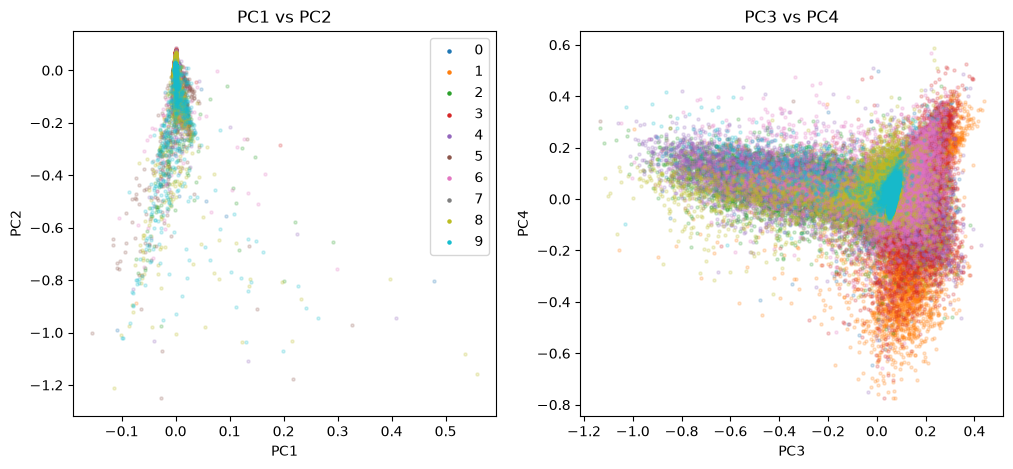

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))
classes = np.unique(y)

for i,c in enumerate(classes):
    mask = (y == c)
    color = f"C{i}" # i-th color of matplotlib's default palette

    ax[0].scatter(Z[mask,0], Z[mask,1], s=5, label=str(c), color=color, alpha=0.20)
    ax[1].scatter(Z[mask,2], Z[mask,3], s=5, label=str(c), color=color, alpha=0.20)

ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[0].set_title("PC1 vs PC2")

ax[1].set_xlabel("PC3")
ax[1].set_ylabel("PC4")
ax[1].set_title("PC3 vs PC4")

legend=ax[0].legend()
for handle in legend.legend_handles:
    handle.set_alpha(1) # The legend would inherit alpha=0.15 otherwise
plt.show()

We see that now the classes are more mixed, making it impossible to make a naive classification rule like in the previous part.

### Task 6
We now want to try to compress the dataset by removing information that would encode noise. Let us start by justifying that we can write

$$
    \boldsymbol X=\begin{bmatrix}
    \vec{x}_1^{\top} \\
    \vec{x}_2^{\top} \\
    \vdots \\
    \vec{x}_M^{\top} \\
    \end{bmatrix}=\overline{\boldsymbol X}+\sum_\alpha \sigma_{\alpha} \vec{u}_\alpha \vec{v}_\alpha^\top
$$

Indeed, since $\boldsymbol X_c = \boldsymbol X - \overline{\boldsymbol X}$, we have that $$\boldsymbol X = \overline{\boldsymbol X}+\boldsymbol X_c=\overline{\boldsymbol X} + U\Sigma V^\top$$

where

$$U\Sigma V^\top = \left( \begin{array}{ccccc} \cdots  \vert & \vec{u}_{\alpha} & \vert \cdots \end{array} \right) \left( \begin{array}{ccc} \ddots & & \\ & \sigma_{\alpha} & \\ & & \ddots \end{array} \right) \left( \begin{array}{c} \vdots\\ \text{---}\ \vec{v}_{\alpha}^{\,T}\ \text{---}\\ \vdots \end{array} \right) = \left( \begin{array}{ccccc} \cdots \vert & \vec{u}_{\alpha} & \vert \cdots \end{array} \right)\left( \begin{array}{c} \vdots\\ \text{---}\ \sigma_\alpha\vec{v}_{\alpha}^{\,T}\ \text{---}\\ \vdots \end{array} \right).$$

This is

$$U\Sigma V^\top=\sum_\alpha \sigma_{\alpha} \vec{u}_\alpha \vec{v}_\alpha^\top$$


### Task 7

By removing in the summation over $\alpha$ the directions that counts for small variance, let's look what happen if we conserve the $[5,10,50,200]$ directions with the largest possible values of $\sigma_{\alpha}$. 

To perform this operation, we'll consider a set of $10$ images, and show the resulting images. We'll make a plot where each line corresponds to a samples that is reconstruted with more and more eigendirections (in column).

Let $K\in\{5,10,50,200\}$. Then, we can define:

$$\boldsymbol X^{(K)}=\overline{\boldsymbol X}+\sum_{\alpha=1}^K \sigma_{\alpha} \vec{u}_\alpha \vec{v}_\alpha^\top = \vec{u}_\alpha \vec{v}_\alpha^{\,T}.$$

Notice that:
$$
\sum_{\alpha=1}^K \sigma_{\alpha} \vec{u}_\alpha \vec{v}_\alpha^\top=\sum_{\alpha=1}^K \sigma_{\alpha}\begin{pmatrix} u_\alpha^1 v_\alpha^1 & \cdots & u_\alpha^1 v_\alpha^j & \cdots & u_\alpha^1 v_\alpha^D \\ \vdots & & \vdots & & \vdots \\ u_\alpha^i v_\alpha^1 & \cdots & u_\alpha^i v_\alpha^j & \cdots & u_\alpha^i v_\alpha^D \\ \vdots & & \vdots & & \vdots \\ u_\alpha^M v_\alpha^1 & \cdots & u_\alpha^M v_\alpha^j & \cdots & u_\alpha^M v_\alpha^D \end{pmatrix}
$$


So given any image $x_i\in\mathbb{R}^{784}$ between the $70.000$ of the data set, if we know $\overline{\boldsymbol X}$ (and note that all the rows of this matrix are $\overline{x}=( ..., \sum_i \frac{x_{ij}}{M}, ...)$, and thus all the information is given by $\overline{x}∈\mathbb{R}^{784})$, it is enough to know $\sigma_1,...,\sigma_K,\vec{u_1},...,\vec{u_K},\vec{v_1},...,\vec{v_K}$ to make a reconstruction of the image by doing:

$$x_i^{(K)}=\overline{x}+\sum_{\alpha=1}^K \sigma_{\alpha} \vec{u}_\alpha \vec{v}_\alpha^\top=\overline{x}+\sum_{\alpha=1}^K \sigma_{\alpha} u_\alpha^i \vec{v}_\alpha^\top.$$

We can compute this for $i\in\{i_1,...,i_{10}\}$ in python as `(U[i, :K] * singular_values[:K]) @ Vt[:K, :]`, which represents the operation

$$
(\sigma_1 u_1^i, ... ,\sigma_K u_K^i)\begin{pmatrix} \text{---} & \vec{v}_1^{\,T} & \text{---} \\ \text{---} & \vec{v}_2^{\,T} & \text{---} \\ & \vdots & \\ \text{---} & \vec{v}_K^{\,T} & \text{---} \end{pmatrix}
$$

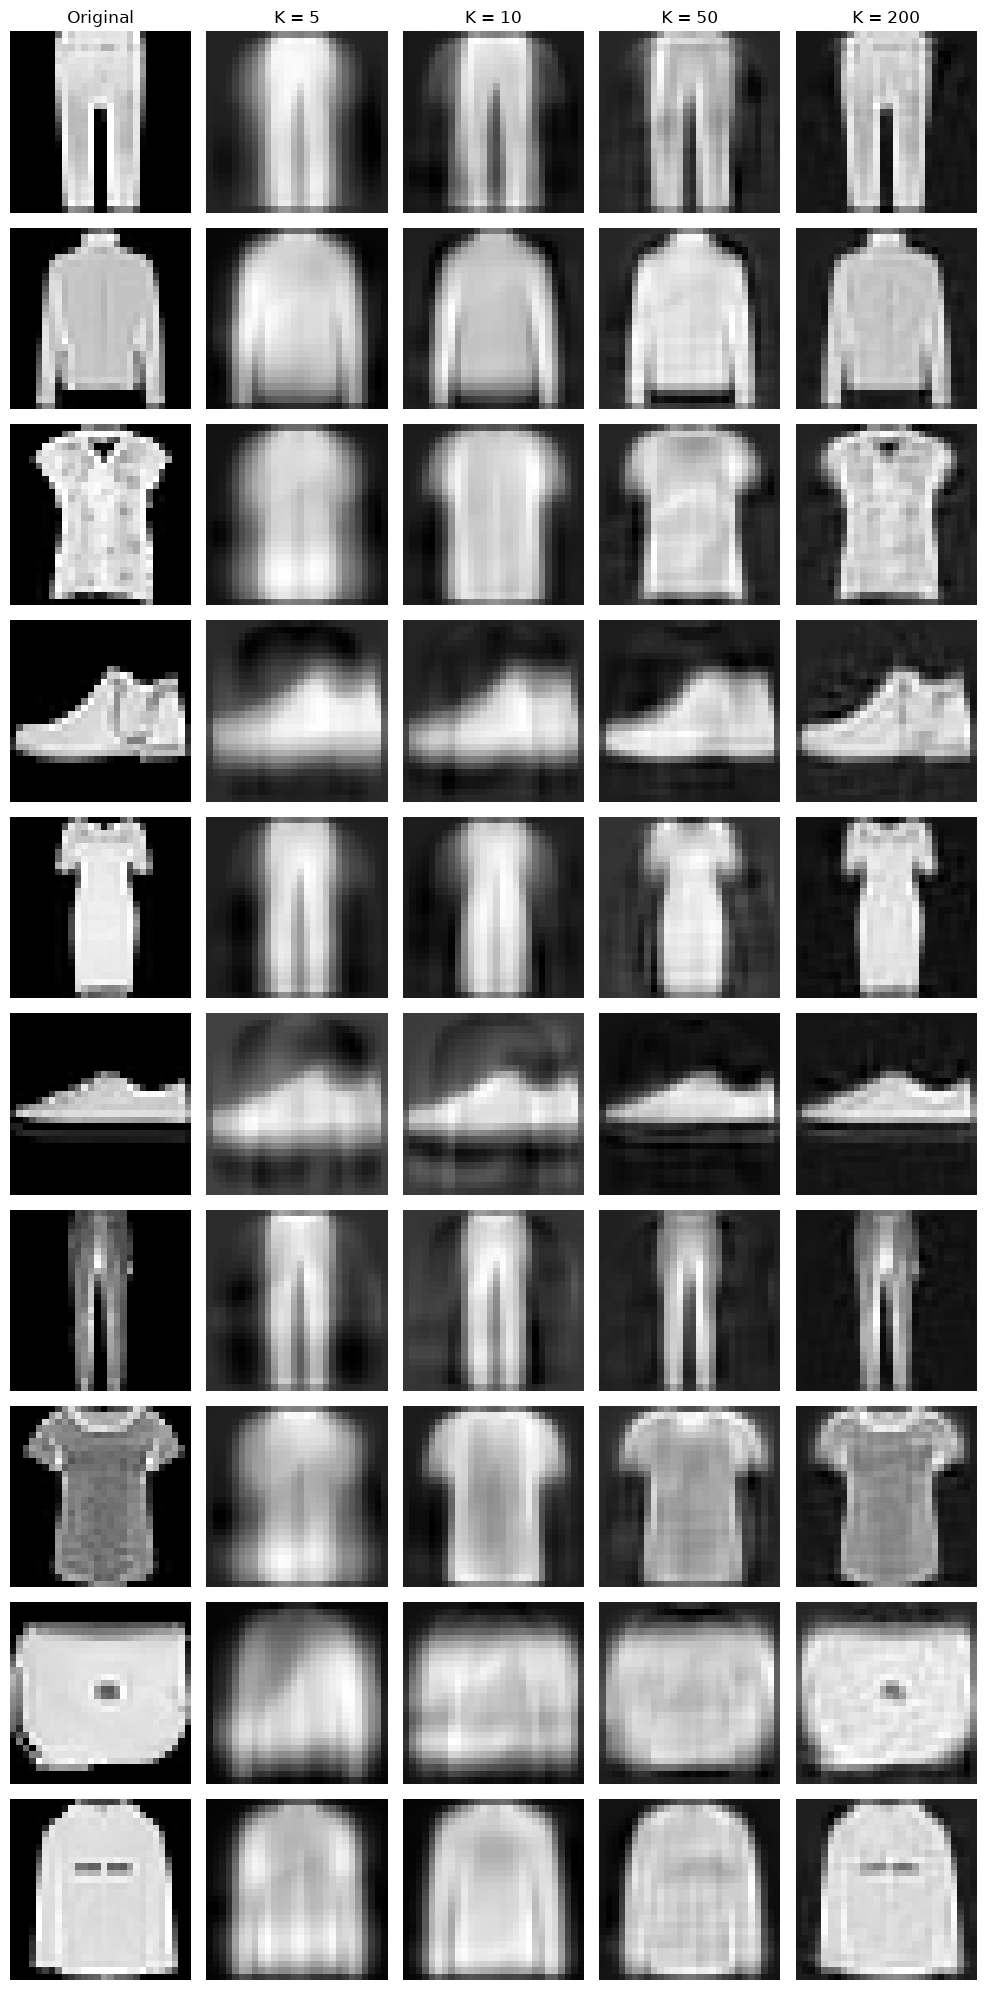

In [23]:
n_components = [5, 10, 50, 200]

# Random selection of 10 images
rng = np.random.default_rng(42)
index = rng.choice(M, size=10, replace=False)

fig, axes = plt.subplots(10, 5, figsize=(10, 20))

for row, idx in enumerate(index):
    # Original images
    axes[row, 0].imshow(X[idx].reshape(28, 28), cmap="gray")
    axes[row, 0].axis("off")

    # Reconstruction
    for col, K in enumerate(n_components, start=1):
        reconstructed = averages + (U[idx, :K] * singular_values[:K]) @ Vt[:K, :]

        axes[row, col].imshow(reconstructed.reshape(28, 28), cmap="gray")
        axes[row, col].axis("off")

# Títulos de las columnas
titles = ["Original", "K = 5", "K = 10", "K = 50", "K = 200"]

for col, title in enumerate(titles):
    axes[0, col].set_title(title)

plt.tight_layout()
plt.show()

---

# Part II: Regression


# Estimator
We consider a problem of polynomial regression.
1. Recall the matrix form of the polynomial regression with one-dimensional inputs, considering a dataset $X \in \mathbb{R}^{n \times 1}$, a set of parameters $\beta \in \mathbb{R}^p$ (here the number of polynomials $p$ can be different from the number of input dimensions) and a set of outputs $\vec{y}\in\mathbb{R}^n$.
2. Give an expression of the estimators of the weights that minimize the loss.
3. Compute the mean and variable using sample theory for the estimators.
4. Using the code below that generate data following a polynomial curve and try to fit it with polynomial of degree 3, 4 and 5. Show by resampling many time the noise on the output the distribution of the estimator, using histograms. How the estimator fluctuate around its means.
5. Show that the estimators are in the confidence interval with the right probability.
6. As the number of samples $n$ increase, could you tell that the polynomial of order 4 or 5 can be reduced to degree 3 ?


### Task 1

Let us recall the matrix form of the polynomial regression with one-dimensional inputs, considering a dataset $X \in \mathbb{R}^{n \times 1}$, a set of parameters $\beta \in \mathbb{R}^p$ (here the degree of the polynomia $p-1$ can be different from the number of input dimensions) and a set of outputs $\vec{y}\in\mathbb{R}^n$.

To do this, start by letting $\{(x_i,y_i)\}_{i=1}^n$ be a labeled data set with $x_i, y_i \in\mathbb{R}$. The regresion problem aims to use the information available in this set to find a function $f$ such that 

$$
    Y = f(X) + \varepsilon =\hat{Y} + \varepsilon,
$$ 

where $\varepsilon$ is the noise term. The polynomial regression restricts $f$ to be a polynomial of degree $p-1$ 

$$
    \hat{Y}=\beta_0+\beta_1X+ \beta_2X^2+...+\beta_{p-1}X^{p-1}.
$$ 

So, for each data point $x_i$ and label $y_i$, we want to find the vector of parameters $\boldsymbol \beta$ such that 

$$
    \hat{y_i}=\beta_0+\beta_1x_i+ \beta_2x_i^2+...+\beta_{p-1}x_i^{p-1}
$$ 

minimices the error comited 

$$
    \sum_{i=1}^n(y_i-\hat{y_i})^2.
$$

Finally, this problem can be presented as a matricial problem:

$$
    \hat{y} = \begin{pmatrix}
                \hat{y_1} \\
                \vdots \\
                \hat{y_n}
            \end{pmatrix} = 
            \begin{pmatrix}
                1 & x_1 & x_1^2 & ... & x_1^{p-1}\\
                \vdots & \vdots & \vdots & \vdots \\
                1 & x_n & x_n^2 & ... & x_n^{p-1}
            \end{pmatrix}
            \begin{pmatrix}
                \beta_0 \\
                \vdots \\
                \beta_{p-1}
                \end{pmatrix} = 
            X\boldsymbol \beta.
$$

### Task 2

Let's now give an expression of the estimators of the weights that minimize the loss.

The loss function is given by 

$$
    L(\boldsymbol{\beta}) = \sum_{i=1}^{n}(y_i-\hat{y}_i)^2 = \|y-X\boldsymbol{\beta}\|^2=(\mathbf{y}-X\boldsymbol{\beta})^T (\mathbf{y}-X\boldsymbol{\beta}).
$$ 

So: 

$$
    L(\boldsymbol{\beta}) = \mathbf{y}^T\mathbf{y} -2\boldsymbol{\beta}^T X^T\mathbf{y} +\boldsymbol{\beta}^T X^T X\boldsymbol{\beta}
$$

This is:

$$
    L(\boldsymbol{\beta}) = \sum_{i=1}^{n}y_i^2 - 2\sum_{i=1}^{n}\sum_{j=0}^{p-1} y_iX_{ij}\beta_j + \sum_{i=1}^{n} \sum_{j=0}^{p-1} \sum_{k=0}^{p-1} X_{ij}X_{ik}\beta_j\beta_k.
$$

This can be shown by expanding patiently the matrix expression. Now, taking partial derivatives:

$$
    \frac{\partial L}{\partial\beta_\ell} = -2\sum_{i=1}^{n}\sum_{j=0}^{p-1} y_i X_{ij}\,\delta_{j\ell} + \sum_{i=1}^{n} \sum_{j=0}^{p-1} \sum_{k=0}^{p-1} X_{ij}X_{ik} \left( \delta_{j\ell}\beta_k + \beta_j\delta_{k\ell} \right).
$$

This is:

$$
    \frac{\partial L}{\partial\beta_\ell} =-2\sum_{i=1}^{n}y_iX_{i\ell} + 2\sum_{i=1}^{n} \sum_{j=0}^{p-1} X_{i\ell}X_{ij}\beta_j.
$$

Then the gradient is:

$$
    \nabla_{\boldsymbol{\beta}} L(\boldsymbol{\beta})=-2X^T y + 2X^T X\boldsymbol{\beta}
$$

The second derivatives are:

$$
    \frac{\partial L}{\partial\beta_r\partial\beta_\ell} =2\sum_{i=1}^{n} \sum_{j=0}^{p-1} X_{i\ell}X_{ij}\delta_{rj}=2\sum_{i=1}^{n} X_{i\ell}X_{ir}.
$$

Then the hessian matrix is

$$
    H=2X^T X
$$

This is a positive semidefinite matrix, since $u^T H u = 2u^T X^T X u = 2\|Xu\|^2 \ge 0,$ and so the loss function is convex. Thus, the parameters where the minimum is reached are the ones that cancel the gradient:
 
$$
    -2X^T y + 2X^T X\boldsymbol{\beta}=0
$$

Note that neither $X^T$ nor $X$ are invertible matrices (they are rectangular, so it doesnt even make sense to invert). But $X^TX\in\mathbb{R}^{p\times p}$ can be invertible, and if it is so, we get

$$
    \boldsymbol{\hat{\beta}} = (X^TX)^{-1}X^T\mathbf y
$$

### Task 3

We are now asked to compute the mean and variance using sample theory for the estimators.

To do this, let's suppose that the noise $\varepsilon=(\varepsilon_1,...,\varepsilon_n)^T$ satisfies $\mathbb E[\varepsilon_i]=0, \mathrm{Var}(\varepsilon_i)=\sigma^2$ for every $i=1,...,n$, and $\varepsilon_1,...,\varepsilon_n$ are independent (this is generally needed to do any interesting computations).

By sustituying $y$ in $\hat{\boldsymbol{\beta}}$ we get:

$$
    \hat{\boldsymbol{\beta}} = (X^TX)^{-1}X^T(X\boldsymbol{\beta}+\boldsymbol{\varepsilon})=(X^TX)^{-1}X^TX\boldsymbol{\beta} + (X^TX)^{-1}X^T\boldsymbol{\varepsilon}.
$$


Since $(X^TX)^{-1}X^TX=I,$ 

$$
    \hat{\boldsymbol{\beta}}= \boldsymbol{\beta} + (X^TX)^{-1}X^T\boldsymbol{\varepsilon}.
$$

Then, if we get the expectation of each $\beta_i$ and arrange them in the vector:

$$
    \mathbb{E}[\hat{\boldsymbol{\beta}}] = \mathbb{E}[\boldsymbol{\beta}] + (X^TX)^{-1}X^T \mathbb{E}[\boldsymbol{\varepsilon}]=\boldsymbol{\beta}.
$$

We get that the estimators $\hat{\boldsymbol{\beta}}$ are unbiased.

Now, the variance-covariance matrix can be computed as

$$
    \operatorname{Var}(\hat{\beta}) = \operatorname{Var}(\boldsymbol{\beta} + (X^TX)^{-1}X^T\boldsymbol{\varepsilon}) = \operatorname{Var} \left((X^TX)^{-1}X^T\varepsilon \right)
$$ 

where we used that the vector of parameters $\boldsymbol{\beta}$ is deterministic and therefore has zero variance.

Lets define $A:=(X^TX)^{-1}X^T$. Then

$$
    \operatorname{Var}(\hat{\beta_i})=\operatorname{Var}(\sum_j A_{ij} \varepsilon_j)=\sum_jA_{ij}^2\sigma^2=\sigma^2\sum_j A_{ij}(A^T)_{ji}=(AA^T)_{ii}
$$

And so, since $X^TX$ (and its inverse) is simetric:

$$
    AA^T = (X^TX)^{-1}X^T X(X^TX)^{-1} = [(X^TX)^{-1}(X^T X)](X^TX)^{-1} = (X^TX)^{-1}
$$

On the other hand,

$$
    \operatorname{Cov}(\hat{\beta_i},\hat{\beta_k}) = \operatorname{Cov}\left(\sum_j A_{ij} \varepsilon_j,\sum_l A_{kl} \varepsilon_l\right) = \sum_j\sum_lA_{ij}A_{kl}\operatorname{Cov}(\varepsilon_j,\varepsilon_l)
$$

But since the noises are independent, we have

$$
    \operatorname{Cov}(\varepsilon_j,\varepsilon_l) = \begin{cases} \sigma^2, & j=l,\\ 0, & j\neq l. \end{cases}
$$

and thus

$$
    \operatorname{Cov}(\hat{\beta_i},\hat{\beta_k}) =  \sigma^2\sum_jA_{ij}A_{kj} =\sigma^2\sum_jA_{ij}(A^T)_{jk}=(AA^T)_{ik}.
$$

We have proved that the variance-covariance matrix is

$$
\operatorname{Var}(\hat{\boldsymbol{\beta}}) = \sigma^2 (X^T X)^{-1}
$$

### Task 4

We'll use the code below that generate data following a polynomial curve, to try and fit it with polynomial of degree 3, 4 and 5.

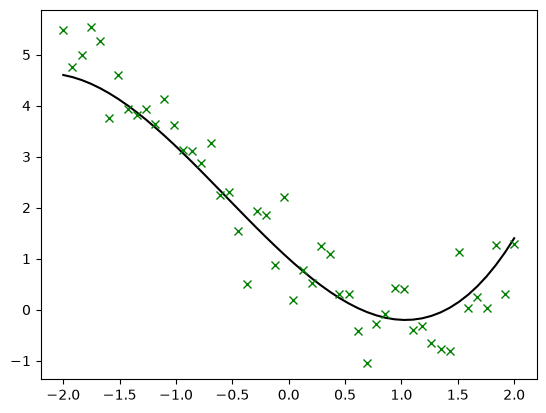

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from scipy.stats import norm

# --- PARAMETERS ---
np.random.seed(0)    # fix the seed
n = 50               # number of data points per sample
n_samples = 5000     # number of Resampling
sigma = 0.5          # noise standard deviation
beta_true = np.array([1.0, -2.0, 0.5, 0.3])   # true cubic polynomial coefficients


# --- DESIGN MATRIX FOR TRUE MODEL ---
x = np.linspace(-2, 2, n) # linearly spanning x in [-2,2]

poly_true = PolynomialFeatures(degree=3, include_bias=True)

X_true = poly_true.fit_transform(x.reshape(-1, 1))
y_true = X_true @ beta_true

plt.plot(x,y_true,label="True function", color='black')

# --- Example of input data
y_noisy = y_true + np.random.normal(0, sigma, size=n)
plt.plot(x,y_noisy, 'x',label="Example of Observed output", color='green')

We'll show (by resampling many time the noise on the output) the distribution of the estimator, using histograms; aswell as how the estimator fluctuate around its means.

In the following code we do exactly that: We resample the noise on each iteration and fit a polinomial of degrees 3, 4 and 5 for each sample. This will give us a vector of parameters for each sample, and so we can plot their distributions in an histogram (higher degree implies more parameters, and thus more histograms).

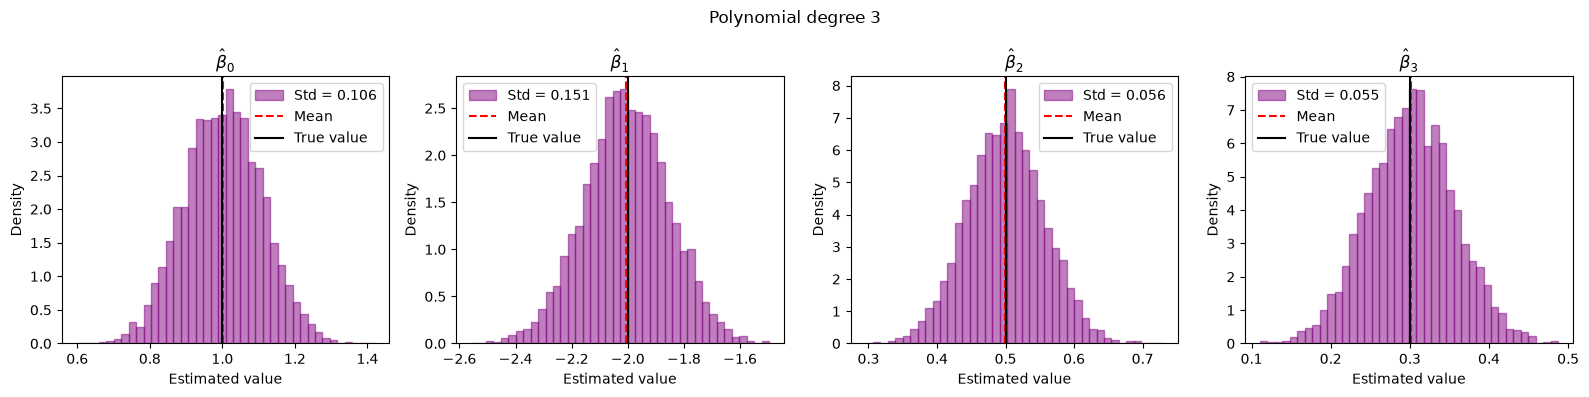

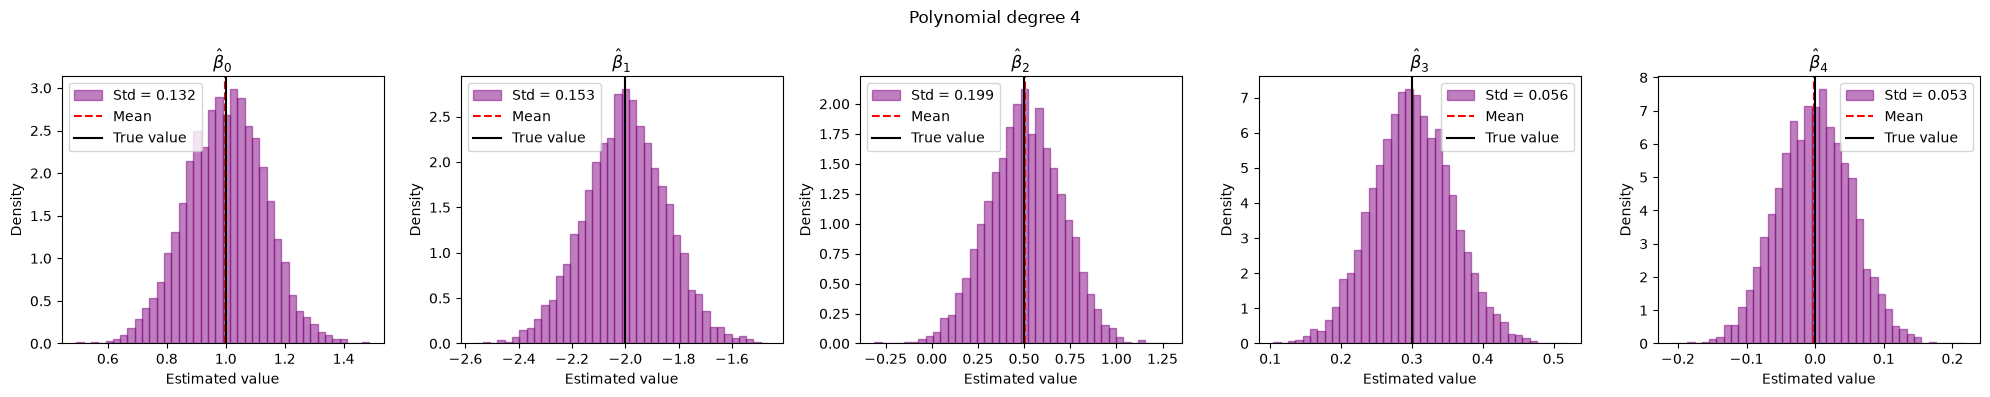

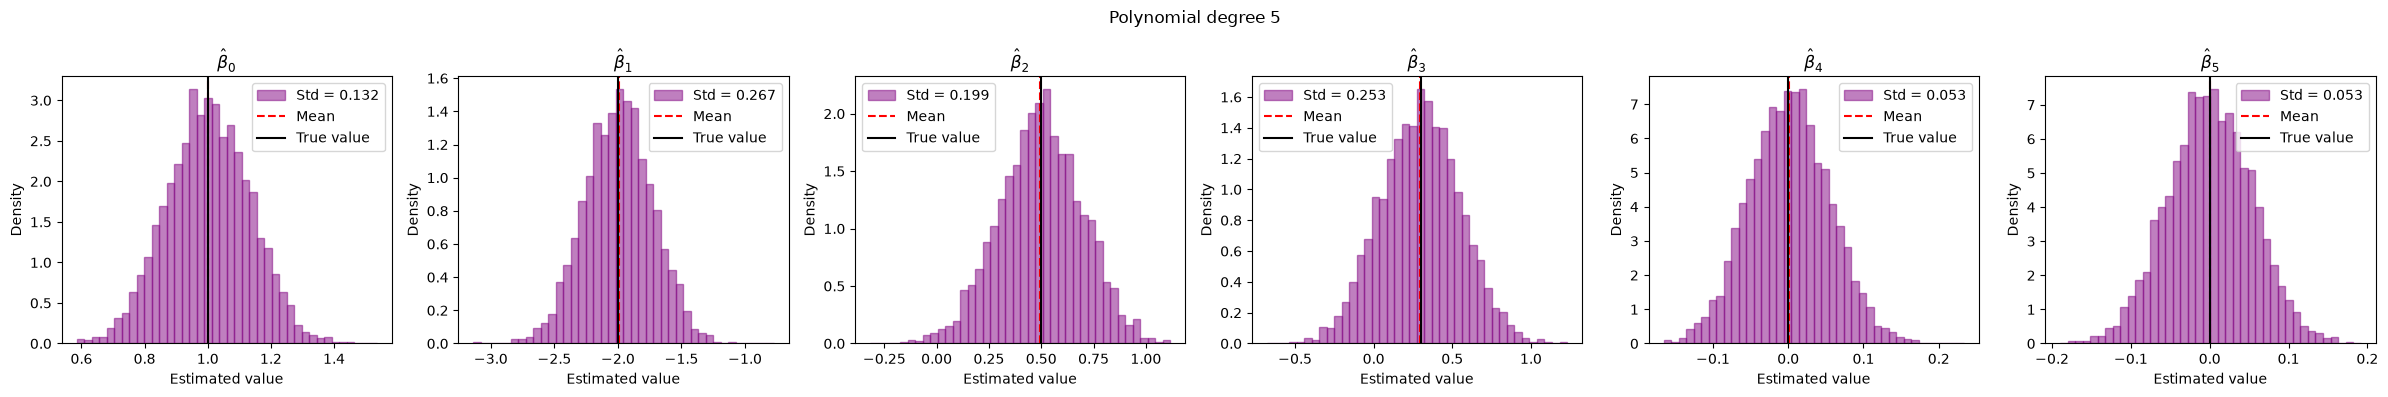

In [25]:
degrees = [3, 4, 5]

all_beta_estimates = {}
all_X = {}
all_beta_true = {}

for degree in degrees:

    poly = PolynomialFeatures(degree=degree, include_bias=True)
    X = poly.fit_transform(x.reshape(-1, 1)) # 50 rows x degree+1 columns

    beta_estimates = np.zeros((n_samples, degree + 1))

    for i in range(n_samples):

        # Resample the noise
        epsilon = np.random.normal(0, sigma, size=n)
        y_sample = y_true + epsilon

        # Compute the estimator
        beta_hat = np.linalg.inv(X.T @ X) @ X.T @ y_sample

        # Store the estimated parameters
        beta_estimates[i, :] = beta_hat

    # True parameters for this polynomial degree
    beta_true_degree = np.zeros(degree + 1)
    beta_true_degree[:len(beta_true)] = beta_true

    # Save results for Task 5
    all_beta_estimates[degree] = beta_estimates
    all_X[degree] = X
    all_beta_true[degree] = beta_true_degree

    # Histograms
    fig, axes = plt.subplots(1, degree + 1, figsize=(4 * (degree + 1), 4))

    for j in range(degree + 1):

        # Empirical standard deviation (shown in the legend, since each plot has its own x scale)
        std_beta = np.std(beta_estimates[:, j])
        axes[j].hist(beta_estimates[:, j], bins=40, density=True, alpha=0.5, label=f"Std = {std_beta:.3f}", color="purple", edgecolor="purple")

        # Empirical mean
        mean_beta = np.mean(beta_estimates[:, j])
        axes[j].axvline(mean_beta, color='red', linestyle='--', label='Mean')

        # True coefficient
        true_beta = beta_true_degree[j]
        axes[j].axvline(true_beta, color='black', label='True value')

        axes[j].set_title(rf"$\hat{{\beta}}_{j}$")
        axes[j].set_xlabel("Estimated value")
        axes[j].set_ylabel("Density")
        axes[j].legend()

    fig.suptitle(f"Polynomial degree {degree}")
    plt.tight_layout()
    plt.show()

Since the estimators are unbiased, the distributions are centered in the real value of the parameters. We notice that some parameters variance is bigger for greater degree polynomials (for instance, $\hat{\beta_2}$). This is because we are allowing the polynomials to be very flexible and, by doing so, we are overfiting to the data, geting more variability.

### Task 5

We'll now show that the estimators are in the confidence interval with the right probability.

In order to get a expresion of the confidence interval, we are going to supose that $\varepsilon_i \sim \mathcal{N}(0,\sigma^2)$. This is a usual hypthesis in regression analysis. Notice that by doing so, since $\hat{\boldsymbol{\beta}}= \boldsymbol{\beta}+
(X^TX)^{-1}X^T\boldsymbol{\varepsilon}$, this is,

$$
\hat{\beta_i}=\beta_i+\sum_jA_{ij}\varepsilon_j
$$

So $\hat{\beta_i}\sim \mathcal{N}(\beta_i,\sigma^2[(X^TX)^{-1})]_{ii})$. On one hand, is normal because is linear combination of normal distributions. On the other, we already computed its mean and variance on Task 3.

This allow us to use, for a given $\alpha$,the pivotal quantity:

$$
Z:=\frac{\hat{\beta}_i-\beta_i}{\sqrt{\sigma^2[(X^TX)^{-1})]_{ii}}}\sim\mathcal{N}(0,1)
$$

Since the distribution of $Z$ is simetric, it is enough to find $k\in\mathbb{R}$ such that

$$
P(-k\leq Z \leq k) = 1-\alpha
$$

Asuming the usual $\alpha=0.05$, we have $k=z_{\alpha/2}=1.96$, and end up geting the confidence interval

$$
IC_{0.95}(\beta_i) = \hat{\beta_i} \pm 1.96\sigma\sqrt{[(X^TX)^{-1})]_{ii}}
$$

From the previous task we got $5.000$ samples of $50$ elements. And so we can construct $5.000$ confidence intervals (made each one with the $50$ points given).

As a simulation of this theoretical proof, we will recount the number of confidence intervals were the real value apears. If we call this quantities $n_j$, the quotient $$\frac{n_j}{5.000}$$ should be close to $0.95$.

In [26]:
alpha = 0.05
k = norm.ppf(1 - alpha / 2)

for degree in degrees:

    X = all_X[degree]
    beta_estimates = all_beta_estimates[degree]
    beta_true_degree = all_beta_true[degree]

    # Standard deviation of each estimator
    std_beta = sigma * np.sqrt(np.diag(np.linalg.inv(X.T @ X)))

    # Confidence intervals for the 5000 estimations
    lower = beta_estimates - k * std_beta
    upper = beta_estimates + k * std_beta

    # Is the true beta inside each confidence interval?
    inside = (lower <= beta_true_degree) & (beta_true_degree <= upper)

    # Proportion of confidence intervals containing the true beta
    coverage = np.mean(inside, axis=0)

    print(f"\nPolynomial degree {degree}")

    for j in range(degree + 1):
        print(f"beta_{j}: {coverage[j]:.4f}")


Polynomial degree 3
beta_0: 0.9528
beta_1: 0.9494
beta_2: 0.9536
beta_3: 0.9496

Polynomial degree 4
beta_0: 0.9504
beta_1: 0.9438
beta_2: 0.9544
beta_3: 0.9456
beta_4: 0.9554

Polynomial degree 5
beta_0: 0.9548
beta_1: 0.9520
beta_2: 0.9538
beta_3: 0.9490
beta_4: 0.9534
beta_5: 0.9480


### Task 6

We are asked: "*As the number of samples $n$ increase, could you tell that the polynomial of order 4 or 5 can be reduced to degree 3?*"

In the case of order 4 or 5 polynomials, the expected value of the parameters $\hat{\beta_4}$ and $\hat{\beta_5}$ are both zero. It is enough to show that variance converges to $0$. We will do this by simulating bigger samples on the degree $5$ polynomial.

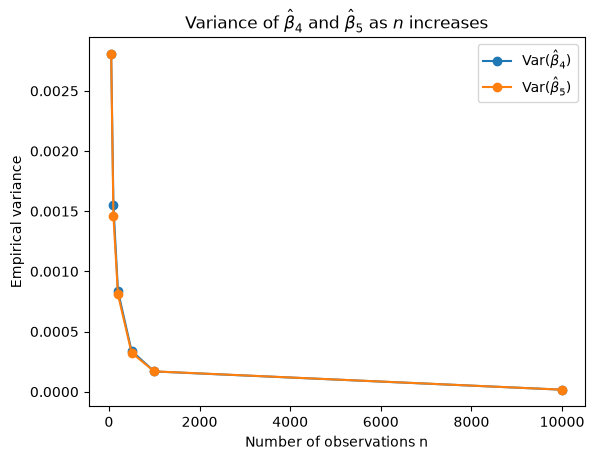

In [27]:
n_values = [50, 100, 200, 500, 1000, 10000]

variances_beta4 = []
variances_beta5 = []

for n in n_values:

    x = np.linspace(-2, 2, n)

    # True cubic model
    X_true = PolynomialFeatures(degree=3, include_bias=True).fit_transform(x.reshape(-1, 1))
    y_true = X_true @ beta_true

    # Degree 5 model
    X = PolynomialFeatures(degree=5, include_bias=True).fit_transform(x.reshape(-1, 1))

    beta_estimates = np.zeros((n_samples, 6))

    for i in range(n_samples):

        y_sample = y_true + np.random.normal(0, sigma, size=n)

        beta_estimates[i, :] = np.linalg.inv(X.T @ X) @ X.T @ y_sample

    variances_beta4.append(np.var(beta_estimates[:, 4]))
    variances_beta5.append(np.var(beta_estimates[:, 5]))


# Plot
plt.plot(n_values, variances_beta4, 'o-', label=r"$\mathrm{Var}(\hat{\beta}_4)$")
plt.plot(n_values, variances_beta5, 'o-', label=r"$\mathrm{Var}(\hat{\beta}_5)$")

plt.xlabel("Number of observations n")
plt.ylabel("Empirical variance")
plt.title(r"Variance of $\hat{\beta}_4$ and $\hat{\beta}_5$ as $n$ increases")
plt.legend()
plt.show()

---

# Model selection with a polynomial

1. Load the dataset, and fit polynomials of order 1,2,...,6. Show the fit of each polynomial.
2. Plot the likelihood function of each polynomials (you can assume that the noise of the data is given by $\sigma=0.6$, but it would be better to try to estimate it...), which one is the best to fit the data ?
3. We are now considering the following posterior distribution on the parameters
$$
    p(\beta_i) = \sqrt{\frac{\alpha}{2\pi}}\exp\left[ -\frac{1}{2}\alpha \beta_i^2 \right]
$$
4. Compute the posterior distribution as a function of $\alpha$ and $\sigma$. What is the posterior mean and variance.
5. For each polynomial fits of degree $k$, compute the evidence
$$
 \mathcal{E}_k = \int d\vec{\beta} p(\vec{\beta}|X,k)
$$
6. Given a list of polynomial fits from order 1 to order 6. Compute the probability of each model using the previously computed evidence and assuming an uniform prior on each model.

### Task 1

Let's start by loading the dataset into a variable named ```X```. This variable is an array of 50 $(x,y)$ points. Since these points are 2D, we can also plot them.

The dimension of X is:  (50, 2)


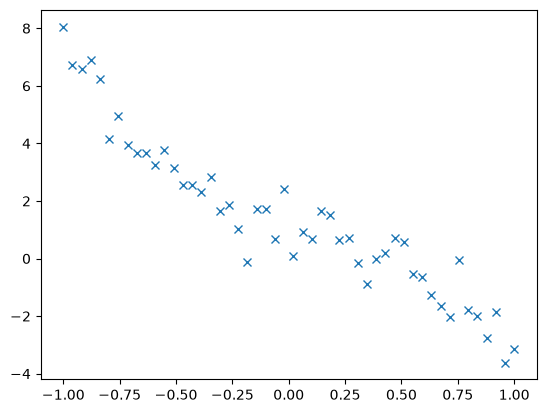

In [28]:
X = np.genfromtxt('DataLW2.d')
print("The dimension of X is: ", X.shape)
plt.plot(X[:,0],X[:,1],'x')

Now, let's fit polynomials of order one through six. We'll plot each fit.

To do this, let's recall the theory we developed on previous tasks. First of all, we need to construct the matrix $X_p$ like:

$$X_p = \begin{pmatrix} 1 & x_1 & x_1^2 & ... & x_1^{p-1} \\ \vdots & \vdots & \vdots & \vdots & \vdots \\ 1 & x_n & x_n^2 & ... & x_n^{p-1} \end{pmatrix}_{n \times p},$$

where $x_i$ is the $x$ coordinate of the i-th $(x,y)$ training point, and $p$ is the degree of the polynomia to fit. Notice that this is a ***Vandermonde matrix*** and, luckily, ```numpy``` has a function for building it easily (```np.vander```)

After that, to obtain the coefficients vector $\boldsymbol{\hat{\beta}}$ of the fitting polynomia, we compute:

$$ \boldsymbol{\hat{\beta}} = (X^TX)^{-1}X^T\mathbf y,$$

where $\mathbf y$ is the vector of $y$ training values.

After that, the fitting polynomia is just:

$$p(t) = \boldsymbol{\hat{\beta}}^T \begin{pmatrix}1 \\ t \\ t^2 \\ \vdots \\ t^{p-1}\end{pmatrix}.$$

With all of this, we are ready to start the task. We'll simplify the fitting process by wrapping it into a function that returns the coefficients $\boldsymbol{\hat{\beta}}$, then we'll make another function for evaluating the polynomia in a set of points given its coefficients.

On a side note, it's easier (and quicker) to evaluate the polynomia in a series of points instead of looping through each point and evaluating the polynomia on the point individually. This can be done by performing the operation:

$$p(T) = \begin{pmatrix} 1 & t_1 & t_1^2 & ... & t_1^{p-1} \\ \vdots & \vdots & \vdots & \vdots & \vdots \\ 1 & t_n & t_n^2 & ... & t_n^{p-1} \end{pmatrix}_{n \times p} \boldsymbol{\hat{\beta}}$$

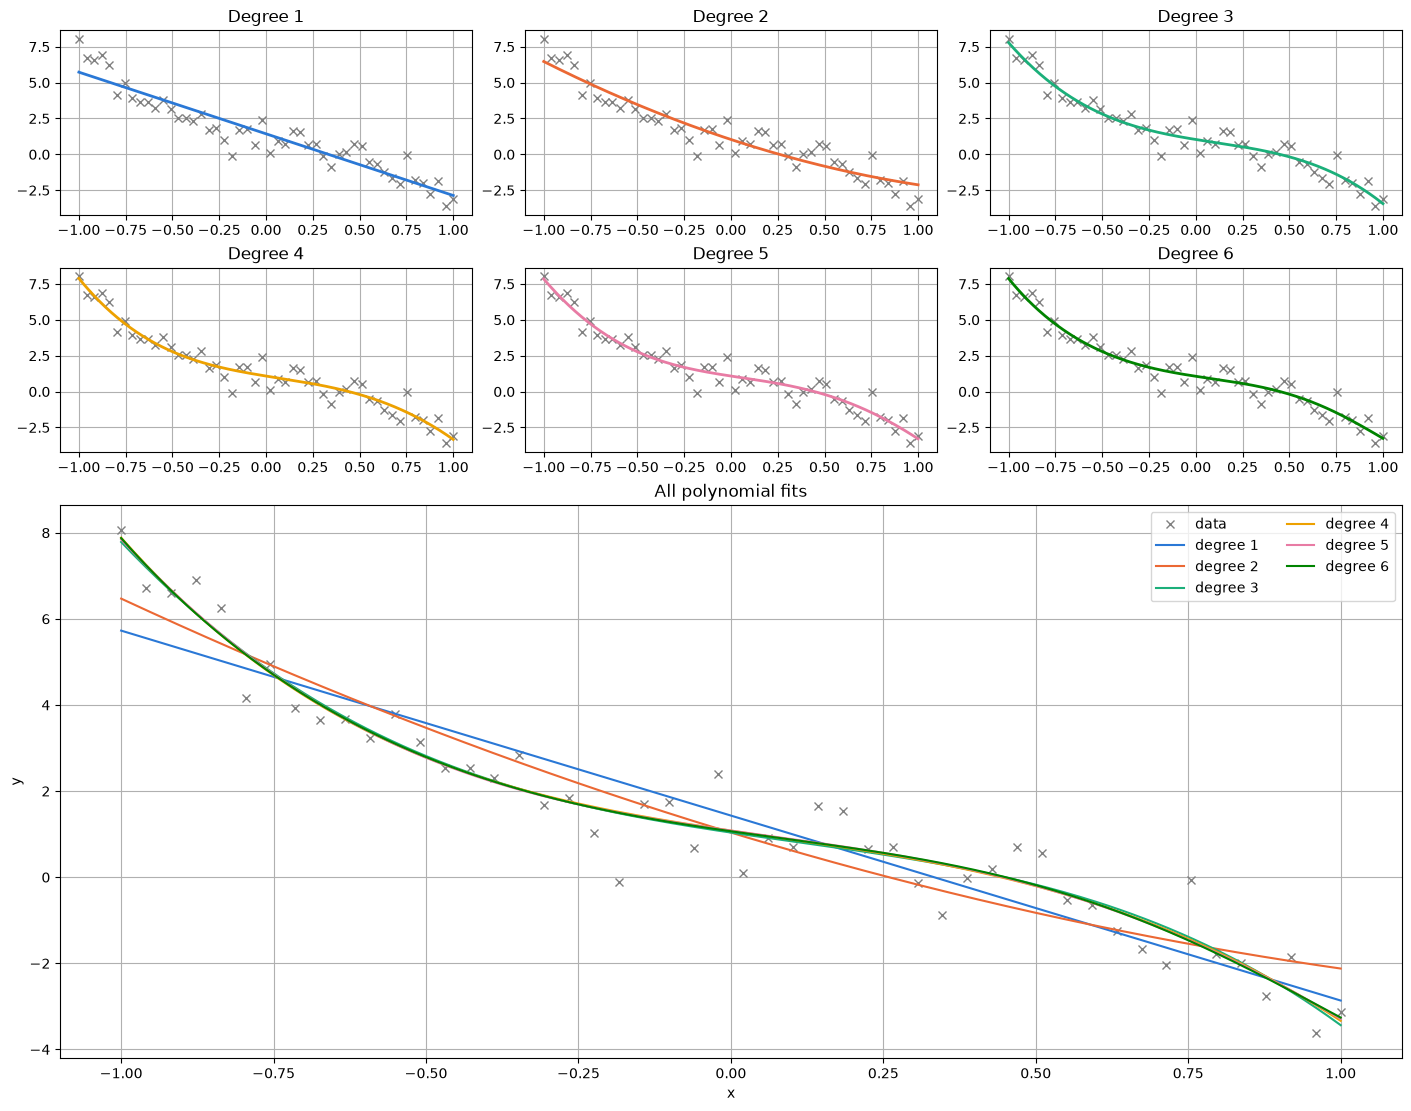

In [29]:
# Functions for handling the obtention of polynomia coefficients and polynomia evaluation
def getFittingPolynomiaCoefficients(xValues : np.ndarray, yValues : np.ndarray, deg : int):
    Xp = np.vander(xValues, N=deg + 1, increasing=True) # Note: deg + 1 because we have to account for the degree 0 element
    betaHat =  np.linalg.inv(Xp.T @ Xp) @ Xp.T @ yValues
    return betaHat

def evalPoly(coefficients : np.ndarray, xValues : np.ndarray):
    deg = len(coefficients)
    T = np.vander(xValues, N=deg, increasing=True)
    return T @ coefficients

# ==== Plotting ==== #
x_train, y_train = X[:, 0], X[:, 1]
degrees = range(1, 7) # End of interval not included -> degrees 1..6

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"] # Cute color palette

xGrid = np.linspace(x_train.min(), x_train.max(), 300)
fits = {d: evalPoly(getFittingPolynomiaCoefficients(x_train, y_train, d), xGrid) for d in degrees}

# Let's set up out plotting grid. Numbered spaces correspond to an individual figure,
# while "all" spaces correspond to a big figure where we'll plot all the polynomials
mosaic = [[1, 2, 3],
          [4, 5, 6],
          ["all", "all", "all"],
          ["all", "all", "all"],
          ["all", "all", "all"]]
_, axd = plt.subplot_mosaic(mosaic, figsize=(14, 11), layout="constrained") # layout constrained so texts don't overlap

# One figure per degree
for d, c in zip(degrees, colors):
    ax = axd[d]
    ax.plot(x_train, y_train, "x", color="gray") # Plots (x,y) points in gray
    ax.plot(xGrid, fits[d], color=c, lw=2)       # Plots (x, p(x)) points in color 'c'
    ax.set_title(f"Degree {d}")
    ax.grid()                                    # Draws the grid lines in the background

# Wide panel with every fit
axAll = axd["all"] # axd is a dictionary that associates a value (1,...,6, "all") to an matplotlib axes object
axAll.plot(x_train, y_train, "x", label="data", color="gray")
for d, c in zip(degrees, colors):
    axAll.plot(xGrid, fits[d], color=c, label=f"degree {d}")
axAll.set_title("All polynomial fits")
axAll.set_xlabel("x")
axAll.set_ylabel("y")
axAll.grid()
axAll.legend(loc="upper right", ncols=2)

plt.show()


We see that after degree 3, almost all the fits are identical. This could be explained by hypothesizing the data comes from a noisy cubic polynomia. We still can't know for sure, further analysis needs to be done.

### Task 2

Like we've discussed before, the underlying assumption of fitting a polynomia to a dataset is that there exists a true (polynomic) function $f_*$ that satisfies

$$y^{true}_i = f_*(x_i),$$

and it is the process of gathering the data that corrupts the information, adding noise:

$$y^{obs}_i = f_*(x_i) + \varepsilon_i$$

In order to obtain the likelihood function of a polynomia, we need to make further assumptions over $\varepsilon = (\varepsilon_1, \ldots, \varepsilon_n)^T$: Rather than just assuming that $\mathbb{E}[\varepsilon_i] = 0$, $\operatorname{Var}(\varepsilon_i) = \sigma^2$, let us assume that $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$.

Now, recall that if we had all the information about the noise, we could fully characterize the distribution of $y_i$ as

$$p(y_i | x_i, \varepsilon_i, \sigma^2, \boldsymbol{\beta}) = \delta\left(y_i - \boldsymbol{\beta}^T \begin{pmatrix}1 \\ x_i \\ x_i^2 \\ \vdots \\ x_i^{p-1}\end{pmatrix} - \varepsilon_i \right).$$

(Note: $x_i$ is considered a deterministic value, while $y_i$ a random variable.)

For the sake of notation, let us call $\tilde{x}_i = (x_i, x_i^2, \ldots, x_i^{p-1})^T$. Then, the previous reasoning allows us to do the following calculation:

$$
\begin{align*}
    p(y_i | x_i, \sigma^2, \boldsymbol{\beta}) &= \int p(y_i, \varepsilon_i | x_i, \sigma^2, \boldsymbol{\beta}) d\varepsilon_i\\
    &= \int p(y_i | x_i, \varepsilon_i, \sigma^2, \boldsymbol{\beta}) p(\varepsilon_i | x_i, \sigma^2) d\varepsilon_i\\
    &= \frac{1}{\sqrt{2\pi \sigma^2}}\int \delta(y_i - \boldsymbol{\beta}^T \tilde{x}_i - \varepsilon_i) \exp\left(-\frac{\varepsilon_i^2}{2\sigma^2}\right) d\varepsilon_i\\
    &= \frac{1}{\sqrt{2\pi \sigma^2}} \exp\left(-\frac{(y_i - \boldsymbol{\beta}^T \tilde{x}_i)^2}{2\sigma^2} \right).
\end{align*}
$$

Assuming the (usual) independance between training examples (samples),

$$
\begin{align*}
p(\{y_i\} | \{x_i\}, \sigma^2, \boldsymbol{\beta}) &= \prod_{i=1}^n p(y_i | x_i, \sigma^2, \boldsymbol{\beta})\\
&=  \left(\frac{1}{\sqrt{2\pi \sigma^2}}\right)^n \exp\left(-\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \boldsymbol{\beta}^T \tilde{x}_i\right)^2\right)
\end{align*}.
$$

Therefore, the likelihood function is:

$$\ell(\boldsymbol{\beta}) = \left(\frac{1}{\sqrt{2\pi \sigma^2}}\right)^n \exp\left(-\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \boldsymbol{\beta}^T \tilde{x}_i\right)^2\right)$$

For the task, we'll use the log-likelihood function (numerical stability, etc...)

$$\log \ell(\boldsymbol{\beta}) = -\frac n2 \log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^n \left(y_i - \boldsymbol{\beta}^T\tilde x_i\right)^2$$

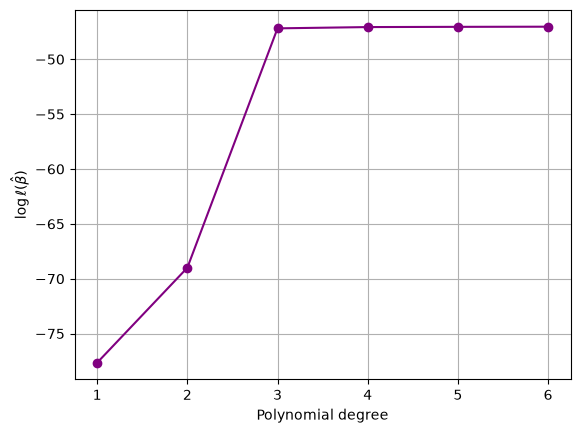

In [30]:
# For starters, we'll start assuming sigma=0.6
sigma = 0.6

n = len(x_train)
logL = []

for d in degrees:
    beta = getFittingPolynomiaCoefficients(x_train, y_train, d)
    residuals = y_train - evalPoly(beta, x_train)
    logL.append(-n/2 * np.log(2*np.pi*sigma**2) - np.sum(residuals**2) / (2*sigma**2))

plt.plot(degrees, logL, "o-", color="purple")
plt.xlabel("Polynomial degree")
plt.ylabel(r"$\log \ell(\hat{\beta})$")
plt.grid()
plt.show()

Notice that the maximum is at degree 6. However, the improvement is almost negligible starting at degree 3.

Let's try to estimate $\sigma$. To do this, we'll start by estimating the error/noise $\varepsilon$:

$$\hat{\boldsymbol\varepsilon} = \boldsymbol{y} - \boldsymbol{\hat{y}} = \tilde{X} \boldsymbol{\beta} + \boldsymbol\varepsilon - (\tilde{X}\hat{\boldsymbol{\beta}}),$$

where

$$\tilde{X} = \begin{pmatrix} 1 & x_1 & x_1^2 & \ldots & x_1^{p-1} \\ \vdots & \vdots & \vdots & \vdots & \vdots \\ 1 & x_n & x_n^2 & \ldots & x_n^{p-1} \end{pmatrix}.$$

Let's now prove that $\tilde{X}^T \hat{\boldsymbol\varepsilon} = 0$. To do this, recall (from Task 2 of the previous exercise) that the gradient of the (squared) norm of the error is:

$$\nabla_{\boldsymbol{\beta}} L(\boldsymbol{\beta})=-2\tilde{X}^T \boldsymbol y + 2\tilde{X}^T \tilde{X}\boldsymbol{\beta},$$

and evaluating at $\hat{\boldsymbol\beta}$ we get:

$$\nabla_{\boldsymbol{\beta}} L(\boldsymbol{\beta})\Big|_{\boldsymbol\beta = \hat{\boldsymbol\beta}}=-2\tilde{X}^T \boldsymbol y + 2\tilde{X}^T \tilde{X}\hat{\boldsymbol{\beta}} = -2\tilde{X}^T(\boldsymbol y - \tilde{X}\hat{\boldsymbol{\beta}}) = -2\tilde{X}^T \hat{\boldsymbol \varepsilon} = 0$$

Let's now define a ***projection matrix*** $Q$ (using that $\boldsymbol{\hat{\beta}} = (\tilde{X}^T\tilde{X})^{-1}\tilde{X}^T\boldsymbol y$ from Task 2, previous exercise) as follows:

$$
\hat{\boldsymbol y} = \tilde{X} \boldsymbol{\hat \beta} = \tilde{X}(\tilde{X}^T\tilde{X})^{-1}\tilde{X}^T\mathbf y = Q \boldsymbol y.
$$

Notice that we are assuming that $(\tilde{X}^T\tilde{X})$ is invertible: that is, the columns of $\tilde{X}$ are linearly independent ($\tilde{X}$ has full column rank $p$). This holds in our case: if $\tilde{X}\boldsymbol a = 0$ for some $\boldsymbol a \in \mathbb{R}^p$, then the polynomial $a_0 + a_1 x + \ldots + a_{p-1}x^{p-1}$ vanishes at every $x_i$, and a nonzero polynomial of degree $p-1$ has at most $p-1$ roots. Since we have $n = 50 \geq p$ distinct $x_i$, we must have $\boldsymbol a = 0$.

It then follows that:
1. (Idempotency) $Q^2 = \big[\tilde{X}(\tilde{X}^T\tilde{X})^{-1}\tilde{X}^T\big]\big[\tilde{X}(\tilde{X}^T\tilde{X})^{-1}\tilde{X}^T\big] = \tilde{X} (\tilde{X}^T\tilde{X})^{-1} (\tilde{X}^T\tilde{X}) (\tilde{X}^T\tilde{X})^{-1} \tilde{X}^T = Q$

2. ($\tilde{X}$ is fixed by $Q$) $Q \tilde{X} = \tilde{X}(\tilde{X}^T\tilde{X})^{-1}\tilde{X}^T \tilde{X} = \tilde{X}$

3. ($Q$ is symmetric) $Q^T = \big[\tilde{X}(\tilde{X}^T\tilde{X})^{-1}\tilde{X}^T\big]^T = \tilde{X}\big[(\tilde{X}^T\tilde{X})^{-1}\big]^T\tilde{X}^T = \tilde{X}(\tilde{X}^T\tilde{X})^{-1}\tilde{X}^T = Q,$ where we used that $\tilde{X}^T\tilde{X}$ is symmetric, and so is its inverse.

Properties 1 and 3 prove that $Q$ is an orthogonal projection onto $\operatorname{Im}(Q)$. Moreover, $\operatorname{Im}(Q) = \operatorname{Im}(\tilde{X})$: since $Q = \tilde{X}\big[(\tilde{X}^T\tilde{X})^{-1}\tilde{X}^T\big]$, every $Qv$ is of the form $\tilde{X}w$, so $\operatorname{Im}(Q) \subseteq \operatorname{Im}(\tilde{X})$; and property 2 gives $\operatorname{Im}(\tilde{X}) \subseteq \operatorname{Im}(Q)$. This proves that $Q$ is an ***orthogonal projection matrix on the subspace $\operatorname{Im}(\tilde{X})$***.

Before wrapping up, let's study briefly the eigenvalues of $Q$. Let $v \neq 0$ be an eigenvector of $Q$ associated to the eigenvalue $\lambda$:

$$ Qv = \lambda v \implies Q^2 v = Q Q v = Q \lambda v = \lambda^2 v, $$

and also,

$$ Q^2 v = Q v = \lambda v.$$

Therefore, since $v \neq 0$,

$$ \lambda^2 v = \lambda v \implies \lambda(\lambda - 1)v = 0 \implies \lambda = 0 \text{ or } \lambda = 1.$$

Since $Q$ is symmetric, it is diagonalizable (spectral theorem), so its rank equals the number of nonzero eigenvalues (counted with multiplicity), that is, the number of eigenvalues equal to $1$. Hence, using $\operatorname{Rank}(Q) = \operatorname{Rank}(\tilde{X}) = p$ (because $\operatorname{Im}(Q) = \operatorname{Im}(\tilde{X})$ and $\tilde{X}$ has full column rank):

$$ \operatorname{Tr}(Q) = \sum_{\lambda \in \operatorname{spec}(Q)} \lambda = \operatorname{Rank}(Q) = p.$$

With all of this, we can perform a lengthy calculation (which we'll skip because, honestly, is kind of large), and obtain

$$
\frac{1}{n} \lVert \hat{\boldsymbol \varepsilon} \rVert^2 = \frac{1}{n}(\boldsymbol{\varepsilon}^T \boldsymbol{\varepsilon} - \boldsymbol {\varepsilon}^T Q \boldsymbol{\varepsilon}),
$$

and with that (another lengthy calculation):

$$
\frac{1}{n} \mathbb{E}\big[\lVert \hat{\boldsymbol{\varepsilon}} \rVert^2\big] = \frac{1}{n}\mathbb{E}[\hat{\boldsymbol\varepsilon}^T \hat{\boldsymbol\varepsilon}] = \frac{1}{n}\mathbb{E}[\boldsymbol{\varepsilon}^T \boldsymbol{\varepsilon}] - \frac{1}{n}\mathbb{E}[\boldsymbol {\varepsilon}^T Q \boldsymbol{\varepsilon}] = \big(n - \operatorname{Tr}(Q)\big)\frac{\sigma^2}{n} = \big(n - p\big)\frac{\sigma^2}{n},
$$

which finally yields the (unbiased) estimator for $\sigma^2$:

$$
\hat{\sigma}^2 = \frac{\lVert \hat{\boldsymbol{\varepsilon}} \rVert^2}{n - p},
$$

Since $\mathbb{E}\big[\lVert \hat{\boldsymbol{\varepsilon}} \rVert^2\big] = (n-p)\sigma^2$, we **define** the estimator by replacing the expectation of the norm with the observed value of the norm.

The estimated values for sigma are:  [0.92665386 0.86278014 0.64740473 0.65313395 0.66025195 0.66771838]


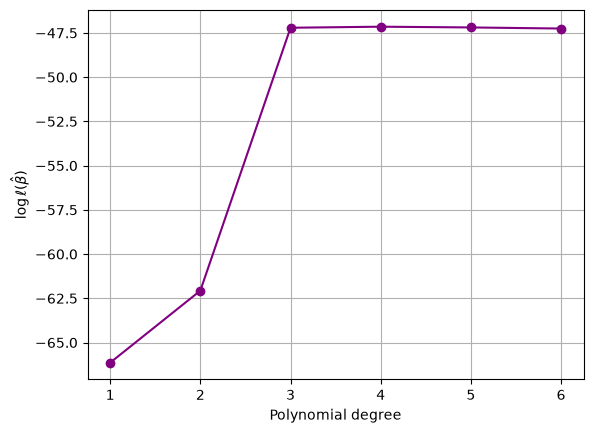

In [31]:
# Now we actually compute the estimated and plot again the likelihood
n = len(x_train)
sigma2_hat = []

for d in degrees:
    beta = getFittingPolynomiaCoefficients(x_train, y_train, d)
    hat_epsilon = y_train - evalPoly(beta, x_train)
    p = d + 1
    sigma2_hat.append(np.sum(hat_epsilon**2) / (n - p))

print("The estimated values for sigma are: ", np.sqrt(sigma2_hat))

logL = []

for i,d in enumerate(degrees):
    beta = getFittingPolynomiaCoefficients(x_train, y_train, d)
    residuals = y_train - evalPoly(beta, x_train)
    logL.append(-n/2 * np.log(2*np.pi*sigma2_hat[i]) - np.sum(residuals**2) / (2*sigma2_hat[i]))

plt.plot(degrees, logL, "o-", color="purple")
plt.xlabel("Polynomial degree")
plt.ylabel(r"$\log \ell(\hat{\beta})$")
plt.grid()

Obviously, the graph doesn't change a lot...

### Task 3 & 4

We are now considering the following a priori distribution on the parameters

$$
    p(\beta_i) = \sqrt{\frac{\alpha}{2\pi}}\exp\left[ -\frac{1}{2}\alpha \beta_i^2 \right]
$$

Let's compute the posterior distribution as a function of $\alpha$ and $\sigma$ and then obtain the posterior mean and variance. Let us assume (obviously) that $\alpha > 0$. It also worth reminding that $\sigma^2$ is the variance of the error/noise, while $\alpha^{-1}$ is the variance of the parameters $\beta_i$ prior to estimating them.

By the expression of the prior, we have that $\beta_i \sim \mathcal{N}(0, 1/\alpha)$. Then, assuming independance over the $\beta_i$, we can deduce the expression for $p(\boldsymbol \beta)$ as follows:

$$
p(\boldsymbol \beta) = p(\beta_0, \ldots, \beta_{p-1}) = \prod_{i=0}^{p-1}p(\beta_i) = \left(\sqrt{\frac{\alpha}{2\pi}}\right)^{p} \exp\left[ -\frac{1}{2}\alpha \sum_{i=0}^{p-1}\beta_i^2 \right].
$$

We can now formulate the posterior probability using Bayes rule:

$$
p(\boldsymbol\beta | \boldsymbol y, X, \sigma^2) = \frac{p(\boldsymbol y | \boldsymbol \beta, X, \sigma^2) p(\boldsymbol \beta)}{\displaystyle\int p(\boldsymbol y | \boldsymbol \beta, X, \sigma^2) p(\boldsymbol \beta) d \boldsymbol \beta},
$$

and, using the expression for $p(\boldsymbol y | \boldsymbol \beta, X, \sigma^2)$ obtained in the previous task along with the expression for $p(\boldsymbol \beta)$ we just obtained, we get:

$$
\begin{align*}
    p(\boldsymbol\beta | \boldsymbol y, X, \sigma^2) &\propto \left(\frac{1}{\sqrt{2\pi \sigma^2}}\right)^n \exp\left(-\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \boldsymbol{\beta}^T \tilde{x}_i\right)^2\right) \left(\sqrt{\frac{\alpha}{2\pi}}\right)^{p} \exp\left[ -\frac{1}{2}\alpha \sum_{i=0}^{p-1}\beta_i^2 \right]\\
    &= \left(\frac{1}{\sqrt{2\pi \sigma^2}}\right)^n \left(\sqrt{\frac{\alpha}{2\pi}}\right)^{p} \exp\left[ -\frac{1}{2}\left(\frac{1}{\sigma^2}\sum_{i=1}^n \left(y_i - \boldsymbol{\beta}^T \tilde{x}_i\right)^2 + \alpha \sum_{i=0}^{p-1}\beta_i^2\right) \right]
\end{align*}
$$

Since we only care about the dependence on $\boldsymbol\beta$, we can drop every factor that does not depend on it. Moreover, writing the sums in matrix form,

$$
\begin{align*}
    &\sum_{i=1}^n \left(y_i - \boldsymbol{\beta}^T \tilde{x}_i\right)^2 = \lVert \boldsymbol y - \tilde{X}\boldsymbol\beta \rVert^2,\\
    &\sum_{i=0}^{p-1}\beta_i^2 = \boldsymbol\beta^T\boldsymbol\beta,
\end{align*}
$$

we have

$$
p(\boldsymbol\beta | \boldsymbol y, X, \sigma^2) \propto \exp\left[ -\frac{1}{2}\left(\frac{1}{\sigma^2}\lVert \boldsymbol y - \tilde{X}\boldsymbol\beta \rVert^2 + \alpha \boldsymbol\beta^T\boldsymbol\beta\right) \right].
$$

Expanding $\lVert \boldsymbol y - \tilde{X}\boldsymbol\beta \rVert^2 = \boldsymbol y^T\boldsymbol y - 2\boldsymbol\beta^T\tilde{X}^T\boldsymbol y + \boldsymbol\beta^T\tilde{X}^T\tilde{X}\boldsymbol\beta$, the term inside the parentheses becomes

$$
\begin{align*}
    \frac{1}{\sigma^2}\lVert \boldsymbol y - \tilde{X}\boldsymbol\beta \rVert^2 + \alpha \boldsymbol\beta^T\boldsymbol\beta &= \frac{1}{\sigma^2}\left(\boldsymbol y^T\boldsymbol y - 2\boldsymbol\beta^T\tilde{X}^T\boldsymbol y + \boldsymbol\beta^T\tilde{X}^T\tilde{X}\boldsymbol\beta \right) + \alpha \boldsymbol\beta^T\boldsymbol\beta\\
    &= \boldsymbol\beta^T \left(\frac{\tilde{X}^T\tilde{X}}{\sigma^2} + \alpha I_p\right) \boldsymbol\beta - 2\boldsymbol\beta^T
    \frac{\tilde{X}^T\boldsymbol y}{\sigma^2} + \frac{\boldsymbol y^T \boldsymbol y}{\sigma^2}.
\end{align*}
$$

The last term does not depend on $\boldsymbol\beta$, so it can be absorbed into the proportionality constant as $\exp[-\frac12\frac{\boldsymbol y^T \boldsymbol y}{\sigma^2}]$.

Let us now define

$$
    A:= \left(\frac{\tilde{X}^T\tilde{X}}{\sigma^2} + \alpha I_p\right)
$$

and

$$
    \boldsymbol b := \frac{\tilde{X}^T\boldsymbol y}{\sigma^2},
$$

so that

$$
    p(\boldsymbol\beta | \boldsymbol y, X, \sigma^2) \propto \exp\left[ -\frac{1}{2}\left(\boldsymbol\beta^T A \boldsymbol\beta - 2\boldsymbol\beta^T \boldsymbol b\right) \right].
$$

Notice that $A$ is symmetric (since $\tilde{X}^T\tilde{X}$ and $I_p$ are) and positive definite, since for every $\boldsymbol v \neq 0$

$$
    \boldsymbol v^T A \boldsymbol v = \frac{1}{\sigma^2}\lVert\tilde{X}\boldsymbol v\rVert^2 + \alpha\lVert\boldsymbol v\rVert^2 > 0,
$$

because $\alpha > 0$. In particular, $A$ is invertible because it is positive definite. This allows us to complete the square:


$$
\begin{align*}
    \boldsymbol\beta^T A \boldsymbol\beta - 2\boldsymbol\beta^T \boldsymbol b + \boldsymbol b^T A^{-1} \boldsymbol b &= \boldsymbol\beta^T A \boldsymbol\beta - \boldsymbol\beta^T \boldsymbol b - \boldsymbol\beta^T \boldsymbol b + \boldsymbol b^T A^{-1} \boldsymbol b\\
    &= \boldsymbol\beta^T A \boldsymbol\beta - \boldsymbol\beta^T \boldsymbol b - \boldsymbol b^T \boldsymbol\beta  + \boldsymbol b^T A^{-1} \boldsymbol b\\
    &= \boldsymbol\beta^T A \boldsymbol\beta - \boldsymbol\beta^T (A A^{-1}) \boldsymbol b - \boldsymbol b^T (A^{-1} A) \boldsymbol\beta + \boldsymbol b^T A^{-1} (A A^{-1}) \boldsymbol b\\
    &= \boldsymbol\beta^T A \boldsymbol\beta - \boldsymbol\beta^T A (A^{-1}\boldsymbol b) - (A^{-1}\boldsymbol b)^T A \boldsymbol\beta + (A^{-1}\boldsymbol b)^T A (A^{-1}\boldsymbol b)\\
    &= \boldsymbol\beta^T A (\boldsymbol\beta - A^{-1}\boldsymbol b) - (A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b)\\
    &= (\boldsymbol\beta^T A - (A^{-1}\boldsymbol b)^T A)(\boldsymbol\beta - A^{-1}\boldsymbol b)\\
    &= (\boldsymbol\beta - A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b),
\end{align*}
$$

where we used $(A^{-1})^T = A^{-1}$ and $\boldsymbol b^T\boldsymbol\beta = \boldsymbol\beta^T\boldsymbol b$ (it is a scalar). Hence

$$
\boldsymbol\beta^T A \boldsymbol\beta - 2\boldsymbol\beta^T \boldsymbol b = (\boldsymbol\beta - A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b) - \boldsymbol b^T A^{-1} \boldsymbol b.
$$

Again, $\boldsymbol b^T A^{-1} \boldsymbol b$ does not depend on $\boldsymbol\beta$, so it can be absorbed into the proportionality constant as $\exp[\frac12 \boldsymbol b^T A^{-1} \boldsymbol b]$, and we get

$$
p(\boldsymbol\beta | \boldsymbol y, X, \sigma^2) \propto \exp\left[ -\frac{1}{2}(\boldsymbol\beta - A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b) \right].
$$

Recall (from what we saw in class with linear regression) that the density of a multivariate normal $\mathcal{N}(\vec{m_n}, V_n)$ is proportional to $\exp\left[-\frac{1}{2}(\boldsymbol\beta - \vec{m_n})^TV_n^{-1}(\boldsymbol\beta - \vec{m_n})\right]$. Then, putting everything together we obtain:

$$
\begin{align*}
    p(\boldsymbol\beta | \boldsymbol y, X, \sigma^2) &= \frac{\left(\frac{1}{\sqrt{2\pi \sigma^2}}\right)^n \left(\sqrt{\frac{\alpha}{2\pi}}\right)^{p} \exp\left[-\frac12\frac{\boldsymbol y^T \boldsymbol y}{\sigma^2}\right]\exp\left[\frac12 \boldsymbol b^T A^{-1} \boldsymbol b\right]\exp\left[ -\frac{1}{2}(\boldsymbol\beta - A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b) \right]}{\left(\frac{1}{\sqrt{2\pi \sigma^2}}\right)^n \left(\sqrt{\frac{\alpha}{2\pi}}\right)^{p} \exp\left[-\frac12\frac{\boldsymbol y^T \boldsymbol y}{\sigma^2}\right]\exp\left[\frac12 \boldsymbol b^T A^{-1} \boldsymbol b\right] \displaystyle\int \exp\left[ -\frac{1}{2}(\boldsymbol\beta - A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b) \right] d \boldsymbol \beta}\\
    &=\frac{\exp\left[ -\frac{1}{2}(\boldsymbol\beta - A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b) \right]}{\displaystyle\int \exp\left[ -\frac{1}{2}(\boldsymbol\beta - A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b) \right] d \boldsymbol \beta}.
\end{align*}
$$

The integral in the denominator is a Gaussian integral (we'll discuss how to solve this in the next task, so right now we just magically paste the result),

$$
    \displaystyle\int \exp\left[ -\frac{1}{2}(\boldsymbol\beta - A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b) \right] d \boldsymbol \beta = \frac{(2\pi)^{p/2}}{\det(A)^{1/2}},
$$

so

$$
p(\boldsymbol\beta | \boldsymbol y, X, \sigma^2) = \frac{\det(A)^{1/2}}{(2\pi)^{p/2}}\exp\left[ -\frac{1}{2}(\boldsymbol\beta - A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b) \right].
$$

And so we obtain exactly the density of a multivariate normal with (posterior) mean $A^{-1}\boldsymbol b$ and (posterior) covariance $A^{-1}$. That is,

$$
\boldsymbol\beta | \boldsymbol y, X \sim \mathcal{N}(\vec{m_n}, V_n),
$$

with

$$
V_n(\sigma^2, \alpha) = A^{-1} = \left(\frac{\tilde{X}^T\tilde{X}}{\sigma^2} + \alpha I_p\right)^{-1}, \qquad \vec{m_n}(\sigma^2, \alpha) = A^{-1}\boldsymbol b = \left(\tilde{X}^T\tilde{X} + \alpha\sigma^2 I_p\right)^{-1}\tilde{X}^T\boldsymbol y.
$$

Degree 1:
   posterior mean: [ 1.407109   -4.09333327]
   posterior variance:  [0.01688379 0.04716605]
Degree 2:
   posterior mean: [ 1.05652384 -4.11919423  1.0348258 ]
   posterior variance:  [0.03008892 0.04114621 0.13194758]
Degree 3:
   posterior mean: [ 1.049106   -2.36574603  1.07619578 -3.0009294 ]
   posterior variance:  [0.0177131  0.10721796 0.07941065 0.22516058]
Degree 4:
   posterior mean: [ 1.08219355 -2.36853682  0.66921293 -2.99472009  0.49722866]
   posterior variance:  [0.01974313 0.10857837 0.3448383  0.22791237 0.3962362 ]
Degree 5:
   posterior mean: [ 1.08216041 -2.45432552  0.66884817 -1.92205132  0.49703303 -1.25190302]
   posterior variance:  [0.02009855 0.11223389 0.34741026 0.5603203  0.39913255 0.45463361]
Degree 6:
   posterior mean: [ 1.09059773 -2.45446056  0.63578114 -1.91792341  0.34375166 -1.25413612
  0.22346836]
   posterior variance:  [0.02121243 0.11384393 0.36105496 0.56187168 0.64310493 0.45683097
 0.51359647]


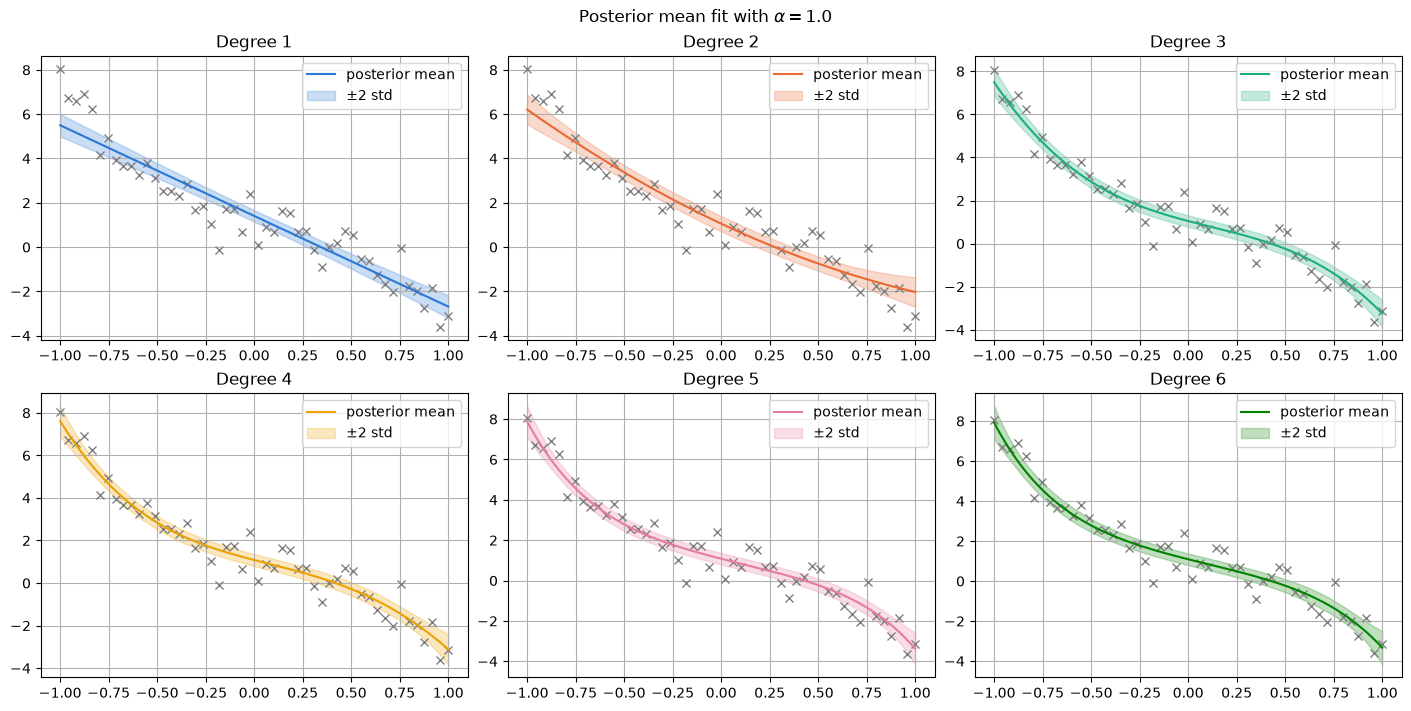

In [32]:
alpha = 1.0 # Choosing this alpha means that every \beta_i is assumed with a normal N(0,1) prior.
            # Changing this value to a bigger one makes the prior "stronger" and shrinks the \beta_i coefficients (because everyone would have an std of 1/\sqrt{\alpha}),
            # on the contrary, changing it to a smaller value gives more "flexibility" and we are closer to the mean square theory
m_n, V_n = {}, {} # Create a dictionary that associates to each degree the posterior mean and posterior covariance

for i, d in enumerate(degrees):
    Xp = np.vander(x_train, N=d + 1, increasing=True)       # +1 again to account for the 0 degree element :)
    A = Xp.T @ Xp / sigma2_hat[i] + alpha * np.eye(d + 1)   # A = X^T X / sigma^2 + alpha I
    b = Xp.T @ y_train / sigma2_hat[i]                      # b = X^T y / sigma^2 (NOTE!! We are using the estimated sigma^2 values in the previous code cell)
    V_n[d] = np.linalg.inv(A)                               # Posterior covariance
    m_n[d] = V_n[d] @ b                                     # Posterior mean
    print(f"Degree {d}:")
    print("   posterior mean:", m_n[d])
    print("   posterior variance: ", np.diag(V_n[d]))       # Take the diagonal because in the diagonal we have the variances, outside of it we have covariances

# Plot: posterior mean polynomial +- 2 std
fig, axes = plt.subplots(2, 3, figsize=(14, 7), layout="constrained")

for ax, d, c in zip(axes.ravel(), degrees, colors):
    mean_curve = evalPoly(m_n[d], xGrid) # This is just the fitting polynomia with the expected coefficients

    # Let's calculate the std of every point of the polynomia (p(t))
    std_curve = np.zeros(len(xGrid))
    for j, t in enumerate(xGrid):
        t_vec = t ** np.arange(d + 1)                  # (1, t, t^2, ..., t^d)
        std_curve[j] = np.sqrt(t_vec @ V_n[d] @ t_vec) # sqrt(t^T V_n t). t^T V_n t = Var(\beta_0 + \beta_1 t + ... \beta_{d} t^{d})

    ax.plot(x_train, y_train, "x", color="gray") # Plot the points in gray as usual
    ax.plot(xGrid, mean_curve, color=c, label="posterior mean") # Plot the polynomia with expected coefficientes
    ax.fill_between(xGrid, mean_curve - 2*std_curve, mean_curve + 2*std_curve, color=c, alpha=0.25, label=r"$\pm 2$ std") # Plot the band between the expected polynomia +- the std (alpha is a transparency parameter for looks)
    ax.set_title(f"Degree {d}")
    ax.legend()
    ax.grid()

fig.suptitle(rf"Posterior mean fit with $\alpha = {alpha}$")
plt.show()

### Task 5

For each polynomial fits of degree $k$, let's compute the evidence

$$
    \mathcal{E}_k = \int p(\boldsymbol y|\boldsymbol \beta, X, \sigma^2, k)\, p(\boldsymbol \beta | k)\, d \boldsymbol \beta = \int_{\mathbb{R}^{p}} p(\boldsymbol y|\boldsymbol \beta, X, \sigma^2)\, p(\boldsymbol \beta)\, d \boldsymbol \beta,
$$

where $p = k + 1$. In the likelihood we can drop $k$, since it is determined by the dimension of $\boldsymbol\beta$. The dependence on $k$ remains, however, through the dimension $p = k+1$ of the space $\mathbb{R}^p$ over which $\boldsymbol\beta$ lives. With that being said, we know from the previous task that:

$$
    \mathcal{E}_k = \left(\frac{1}{\sqrt{2\pi \sigma^2}}\right)^n \left(\sqrt{\frac{\alpha}{2\pi}}\right)^{p} \exp\left[-\frac12\frac{\boldsymbol y^T \boldsymbol y}{\sigma^2}\right]\exp\left[\frac12 \boldsymbol b^T A^{-1} \boldsymbol b\right] \displaystyle\int \exp\left[ -\frac{1}{2}(\boldsymbol\beta - A^{-1}\boldsymbol b)^T A (\boldsymbol\beta - A^{-1}\boldsymbol b) \right] d \boldsymbol \beta
$$

Let us compute

$$
    I = \displaystyle\int_{\mathbb{R}^p} \exp\left[-\frac12(\boldsymbol\beta - \vec{m_n})^T A (\boldsymbol\beta - \vec{m_n})\right] d\boldsymbol\beta,
$$

where $\vec{m}_n = A^{-1}\boldsymbol b$. The first step is to consider the change of variables $\boldsymbol u = \boldsymbol\beta - \vec{m_n}$ ($d\boldsymbol\beta = d\boldsymbol u$):

$$
    I = \int_{\mathbb{R}^p} \exp\left[-\frac12 \boldsymbol u^T A \boldsymbol u\right] d\boldsymbol u.
$$

Since $A$ is symmetric (proved in the previous task!), by the spectral theorem $A = U \Lambda U^T$, with $U$ orthogonal and $\Lambda = \operatorname{diag}(\lambda_1, \ldots, \lambda_p)$. Since $A$ is positive definite (also proved in the previous task!), $\lambda_j > 0$ for all $j$. This allows us to introduce the change of variables $\boldsymbol z = U^T \boldsymbol u$ (since $U$ is orthogonal, $|\det U| = 1$ and $d\boldsymbol u = d\boldsymbol z$), and we get

$$
    \boldsymbol u^T A \boldsymbol u = \boldsymbol z^T U^T U \Lambda U^T U \boldsymbol z = \boldsymbol z^T \Lambda \boldsymbol z = \sum_{j=1}^p \lambda_j z_j^2,
$$

so, substituting in $I$,

$$
    I = \displaystyle \int_{\mathbb{R}^p} \exp\left[-\frac12 \sum_{j=1}^p \lambda_j z_j^2\right] d\boldsymbol z = \prod_{j=1}^p \displaystyle \int_{\mathbb{R}} \exp\left[-\frac12 \lambda_j z_j^2\right] dz_j
$$

where we used Tonelli's theorem (the integrand is positive). We then notice that each factor is a 1D Gaussian integral: with the change of variables $w = \sqrt{\lambda_j}\, z_j$, we get:

$$
    \int_{\mathbb{R}} \exp\left[-\frac12 \lambda_j z_j^2\right] dz_j = \frac{1}{\sqrt{\lambda_j}} \int_{\mathbb{R}} e^{-w^2/2}\, dw = \sqrt{\frac{2\pi}{\lambda_j}}.
$$

Therefore, since $\det A = \prod_{j=1}^p \lambda_j$,

$$
    I = \prod_{j=1}^p \sqrt{\frac{2\pi}{\lambda_j}} = \frac{(2\pi)^{p/2}}{\sqrt{\prod_{j=1}^p \lambda_j}} = \frac{(2\pi)^{p/2}}{\det(A)^{1/2}}.    
$$

And putting everything together nicely we have:

$$
    \mathcal{E}_k = \left(\frac{1}{\sqrt{2\pi \sigma^2}}\right)^n \left(\sqrt{\frac{\alpha}{2\pi}}\right)^{p} \exp\left[-\frac12\frac{\boldsymbol y^T \boldsymbol y}{\sigma^2}\right]\exp\left[\frac12 \boldsymbol b^T A^{-1} \boldsymbol b\right] \frac{(2\pi)^{p/2}}{\det(A)^{1/2}}
$$

We can give an even nicer form: since $\left(\frac{1}{2\pi}\right)^{p/2}(2\pi)^{p/2} = 1$ and $A^{-1}\boldsymbol b = \vec{m_n}$, the previous simplifies to

$$
    \mathcal{E}_k = (2\pi\sigma^2)^{-n/2}\, \alpha^{p/2}\, \det(A)^{-1/2} \exp\left[-\frac12\left(\frac{\boldsymbol y^T\boldsymbol y}{\sigma^2} - \boldsymbol b^T \vec{m_n}\right)\right],
$$

and, taking logarithms (for numerical stability and so on...),

$$
    \log \mathcal{E}_k = -\frac n2 \log(2\pi\sigma^2) + \frac p2 \log\alpha - \frac12 \log\det(A) - \frac12\left(\frac{\boldsymbol y^T\boldsymbol y}{\sigma^2} - \boldsymbol b^T \vec{m_n}\right).
$$

log-evidence per degree: [np.float64(-79.50527943177843), np.float64(-76.77050825209116), np.float64(-62.3926448564778), np.float64(-62.54250516260541), np.float64(-61.220155463387805), np.float64(-61.52283167127287)]


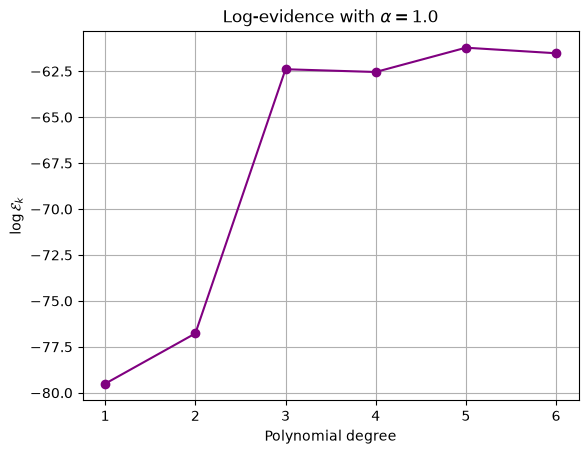

In [33]:
alpha = 1.0 # Same reasoning over \alpha as in the previous task

logE = []

for i, d in enumerate(degrees):
    p = d + 1                                           # Number of coefficients
    Xp = np.vander(x_train, N=p, increasing=True)
    s2 = sigma2_hat[i]                                  # Estimated sigma^2 for this degree
    A = Xp.T @ Xp / s2 + alpha * np.eye(p)              # A = X^T X / sigma^2 + alpha I
    b = Xp.T @ y_train / s2                             # b = X^T y / sigma^2
    m = np.linalg.inv(A) @ b                            # m_n = A^{-1} b

    logE.append(-n/2 * np.log(2*np.pi*s2)                 # -(n/2) log(2 pi sigma^2)
                + p/2 * np.log(alpha)                     # +(p/2) log(alpha)
                - 0.5 * np.log(np.linalg.det(A))          # -(1/2) log det(A)
                - 0.5 * (y_train @ y_train / s2 - b @ m)) # -(1/2)(y^T y / sigma^2 - b^T m_n)

print("log-evidence per degree:", logE)

plt.plot(degrees, logE, "o-", color="purple")
plt.xlabel("Polynomial degree")
plt.ylabel(r"$\log \mathcal{E}_k$")
plt.title(rf"Log-evidence with $\alpha = {alpha}$")
plt.grid()
plt.show()

The graph looks painfully similar to the ones in Task 1 and 2. Next Task will, in fact, let us (finally) deduce which degree yield the polynomia of best fit, regardless of what the likelihood function suggests. This is because, by then, we've been only dealing with information from the data. Now that we introduced a prior on the parameters, we can uso Bayesian techniques. Let's wrap it up in the next Task :)

### Task 6

Given a list of polynomial fits from order 1 to order 6, we want to compute the probability of each model using the previously computed evidence and assuming an uniform prior on each model; that is, $P(k) = \frac16$, where $k \in \{1, \ldots, 6\}$. Using Bayes rule:

$$
P(k | \boldsymbol y, X, \sigma^2, \alpha) = \frac{p(\boldsymbol y | X, \sigma^2, \alpha, k)\, P(k)}{\displaystyle\sum_{j=1}^{6} p(\boldsymbol y | X, \sigma^2, \alpha, j)\, P(j)},
$$

where, as in the previous tasks, $X$ (the inputs $x_i$), $\sigma^2$ and $\alpha$ are fixed values, so we always condition on them.

Notice that $p(\boldsymbol y | X, \sigma^2, \alpha, k)$ is precisely the evidence computed in Task 5. Indeed, by the law of total probability (marginalizing over $\boldsymbol\beta$) and conditional probability,

$$
p(\boldsymbol y | X, \sigma^2, \alpha, k) = \int p(\boldsymbol y, \boldsymbol\beta | X, \sigma^2, \alpha, k)\, d\boldsymbol\beta = \int p(\boldsymbol y | \boldsymbol\beta, X, \sigma^2, k)\, p(\boldsymbol\beta | \alpha, k)\, d\boldsymbol\beta = \mathcal{E}_k,
$$

where we used that the likelihood ($p(\boldsymbol y| X, \sigma^2, \boldsymbol \beta)$) does not depend on $\alpha$ and the prior ($p(\boldsymbol \beta)$) does not depend on $X$ nor $\sigma^2$. This is also the normalizing constant (denominator) of the posterior $p(\boldsymbol\beta | \boldsymbol y, X, \sigma^2, \alpha, k)$ obtained in Tasks 3 & 4.

Since the prior on the models is uniform, it cancels out and we get

$$
P(k | \boldsymbol y, X, \sigma^2, \alpha) = \frac{\mathcal{E}_k}{\displaystyle\sum_{j=1}^{6} \mathcal{E}_j}.
$$

Finally, since the evidences are very small numbers (of order $e^{-60}$, like we saw in the code of the previous Task), we compute this from the log-evidences, subtracting their maximum $c = \max_j \log\mathcal{E}_j$ (which cancels out in the quotient because it's the same as multiplying in the numerator and the denominator by $e^{-c}$, thus the result is unnafected!):

$$
P(k | \boldsymbol y, X, \sigma^2, \alpha) = \frac{\exp(\log\mathcal{E}_k - c)}{\displaystyle\sum_{j=1}^{6} \exp(\log\mathcal{E}_j - c)}.
$$

On a final note, in the code, $\sigma^2$ is replaced by its estimate $\hat\sigma^2$ obtained in Task 2 for each degree.

P(k | y): [4.94688057e-09 7.62127194e-08 1.33737806e-01 1.15125277e-01
 4.31976246e-01 3.19160590e-01]


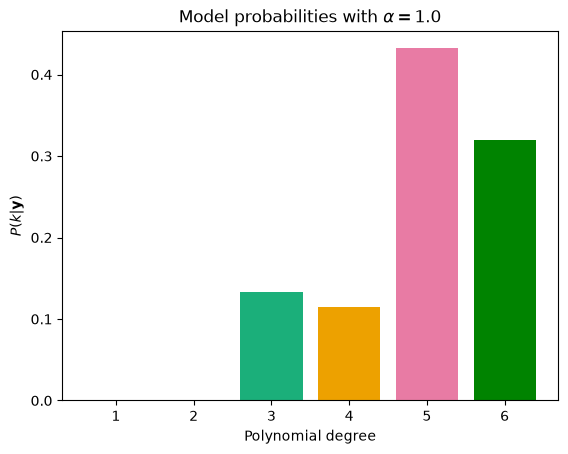

In [34]:
logE = np.array(logE)
probs = np.exp(logE - logE.max())   # Subtract c = max log-evidence (cancels out in the quotient)
probs /= probs.sum()                # P(k | y) = E_k / sum_j E_j

print("P(k | y):", probs)

plt.bar(degrees, probs, color=colors)
plt.xlabel("Polynomial degree")
plt.ylabel(r"$P(k | \mathbf{y})$")
plt.title(rf"Model probabilities with $\alpha = {alpha}$")
plt.show()

Everything seems to point at degree 5 for the best fit polynomia... However, notice that the evidence $\mathcal{E}_k$ depends on $\alpha$! And, since the evidence is proportional to the model probability, we can look for the $\alpha_k$ that maximizes the evidence for the polynomia of degree $k$ (and thus the probability of that model) and then keep the model/polynomia (using its maximizing $alpha$) tha maxes out the model probability.

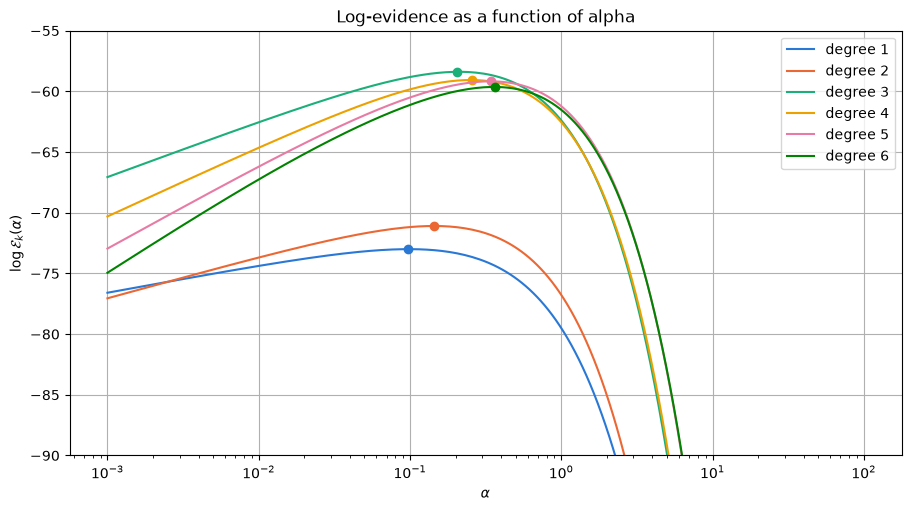

Degree 1: best alpha = 0.097, log-evidence = -73.00
Degree 2: best alpha = 0.145, log-evidence = -71.09
Degree 3: best alpha = 0.205, log-evidence = -58.39
Degree 4: best alpha = 0.258, log-evidence = -59.07
Degree 5: best alpha = 0.345, log-evidence = -59.18
Degree 6: best alpha = 0.365, log-evidence = -59.64


In [35]:
# Same formula as in Task 5, wrapped in a function so we can evaluate it for many alphas
def logEvidence(d, alpha, s2): # (degree, alpha, estimated sigma^2)
    p = d + 1
    Xp = np.vander(x_train, N=p, increasing=True)
    A = Xp.T @ Xp / s2 + alpha * np.eye(p)
    b = Xp.T @ y_train / s2
    m = np.linalg.inv(A) @ b
    return (-n/2 * np.log(2*np.pi*s2)
            + p/2 * np.log(alpha)
            - 0.5 * np.log(np.linalg.det(A))
            - 0.5 * (y_train @ y_train / s2 - b @ m))

alphas = np.logspace(-3, 2, 200)   # 200 values between 10^-3 and 10^2, log-spaced (uniformly spaced in logarithmic scale. This way we can have many orders of magnitude and values)

best_alpha, best_logE = [], []
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")

for i, d in enumerate(degrees):
    curve = [logEvidence(d, a, sigma2_hat[i]) for a in alphas]    # log E_k(alpha) curve for every alpha
    j = np.argmax(curve)                                          # Index of the maximum
    best_alpha.append(alphas[j])
    best_logE.append(curve[j])
    ax.plot(alphas, curve, color=colors[i], label=f"degree {d}")
    ax.plot(alphas[j], curve[j], "o", color=colors[i])            # Mark the optimum

ax.set_xscale("log")
ax.set_ylim(-90, -55) # Otherwise the plot is not correctly visualized (looks squished)
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$\log \mathcal{E}_k(\alpha)$")
ax.set_title("Log-evidence as a function of alpha")
ax.grid()
ax.legend()
plt.show()

for d, a, l in zip(degrees, best_alpha, best_logE):
    print(f"Degree {d}: best alpha = {a:.3f}, log-evidence = {l:.2f}")

And with this, we can clearly conclude that degree 3 is the best fit polynomia! A result based on not only the data, but the Bayesian framework!!